# Real Estate Price Prediction — Valoriza Imóveis Brasil

## Sprint 0 — Auditoria dos dados

**Fonte:** Prefeitura de São Paulo — registros de ITBI.

**Objetivo:** avaliar a qualidade dos dados de transações imobiliárias para desenvolver um modelo de previsão de preços de apartamentos.

**Importante:** os valores de transação são declarados pelos contribuintes e não representam necessariamente preços de venda verificados independentemente.

In [2]:

from pathlib import Path
import pandas as pd

# Localização do arquivo original
CAMINHO_EXCEL = (
    Path("data")
    / "raw"
    / "GUIAS DE ITBI PAGAS (28012026) XLS.xlsx"
)

print("Arquivo encontrado:", CAMINHO_EXCEL.exists())

if not CAMINHO_EXCEL.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {CAMINHO_EXCEL.resolve()}"
    )

# Consultar a estrutura sem carregar todas as planilhas
with pd.ExcelFile(CAMINHO_EXCEL, engine="openpyxl") as excel:
    abas = excel.sheet_names

    print("\nPlanilhas disponíveis:")
    for aba in abas:
        print("-", aba)

    # Ler somente cinco registros da primeira planilha
    amostra = pd.read_excel(
        excel,
        sheet_name=abas[0],
        nrows=5
    )

print("\nDimensões da amostra:", amostra.shape)
display(amostra)


Arquivo encontrado: True



Planilhas disponíveis:
- JAN-2025
- FEV-2025
- MAR-2025
- ABR-2025
- MAI-2025
- JUN-2025
- JUL-2025
- AGO-2025
- SET-2025
- OUT-2025
- NOV-2025
- DEZ-2025
- LEGENDA
- EXPLICAÇÕES
- Tabela de USOS
- Tabela de PADRÕES

Dimensões da amostra: (5, 28)


,N° do Cadastro (SQL),Nome do Logradouro,Número,Complemento,Bairro,Referência,CEP,Natureza de Transação,Valor de Transação (declarado pelo contribuinte),Data de Transação,...,Situação do SQL,Área do Terreno (m2),Testada (m),Fração Ideal,Área Construída (m2),Uso (IPTU),Descrição do uso (IPTU),Padrão (IPTU),Descrição do padrão (IPTU),ACC (IPTU)
0,30106900789,AV CARLOS QUEIROZ TELLES,99999,Apto 163 Bloc L,IBIRAPUERA,NaN,5704150,1.Compra e venda,625100.00,2024-12-20,...,Ativo Territorial,8066,8.00,1.0000,0,0,TERRENO,0,TERRENO,NaN
1,17130212951,R DR LUIZ MIGLIANO,1870,APTO 223 TORRE E,COND MONUMENTO SP,NaN,5711001,1.Compra e venda,573915.07,2024-12-20,...,Ativo Territorial,59923,256.24,0.5155,0,0,TERRENO,0,TERRENO,NaN
2,9900500245,R CAP JOSE INACIO DO ROSARIO,133,AP 2015 TORRE B,LAPA,NaN,5038070,1.Compra e venda,288435.00,2024-12-20,...,Ativo Predial,22903,0.00,1.0000,11382,71,ESCOLA,94,"TEMPLO, CLUBE, GINÁSIO OU ESTÁDIOESPORTIVO, MU...",2002.0
3,2601502142,R MARCOS ARRUDA,729,AP 2411 T A,BELENZINHO,NaN,3020000,1.Compra e venda,237000.00,2024-12-20,...,Ativo Predial,13221,137.95,1.0000,33835,71,ESCOLA,44,COMERCIAL VERTICAL,1959.0
4,1904806211,R NEWTON PRADO,767,AP 136B E VG,COND ESTILO,TORRE B,1127000,4.Arrematação (em leilão ou hasta pública),251576.26,2024-12-18,...,Ativo Predial,5199,55.50,0.0048,95,20,APARTAMENTO EM CONDOMÍNIO (EXIGE FRAÇÃO IDEAL),22,RESIDENCIAL VERTICAL,2014.0


### Critérios iniciais de elegibilidade

Para selecionar registros candidatos ao modelo, aplicaremos cinco condições:

1. Natureza da transação igual a `1.Compra e venda`.
2. Uso cadastral IPTU igual a `20` (apartamento em condomínio).
3. Valor declarado da transação maior que zero.
4. Área construída maior que zero.
5. Proporção transmitida igual a 100%.

Esses critérios são preliminares. Ainda será necessário auditar duplicidades, datas e valores extremos.

In [3]:

# Trabalhar somente com a amostra já carregada
dados = amostra.copy()

# Verificar as cinco condições separadamente
compra_venda = (
    dados["Natureza de Transação"] == "1.Compra e venda"
)

apartamento = (
    dados["Uso (IPTU)"] == 20
)

valor_positivo = (
    dados["Valor de Transação (declarado pelo contribuinte)"] > 0
)

area_positiva = (
    dados["Área Construída (m2)"] > 0
)

transmissao_integral = (
    dados["Proporção Transmitida (%)"] == 100
)

# Exibir quantos registros atendem a cada condição
print("Total da amostra:", len(dados))
print("Compra e venda:", compra_venda.sum())
print("Apartamentos:", apartamento.sum())
print("Valor positivo:", valor_positivo.sum())
print("Área positiva:", area_positiva.sum())
print("Transmissão integral:", transmissao_integral.sum())

# Aplicar todas as condições simultaneamente
elegiveis = dados[
    compra_venda
    & apartamento
    & valor_positivo
    & area_positiva
    & transmissao_integral
].copy()

print("\nRegistros elegíveis:", len(elegiveis))


Total da amostra: 5
Compra e venda: 4
Apartamentos: 1
Valor positivo: 5
Área positiva: 3
Transmissão integral: 1

Registros elegíveis: 0


In [4]:

print("Valores de proporção transmitida na amostra:")
print(amostra["Proporção Transmitida (%)"].to_list())

print("\nTipos de dados das colunas principais:")
print(
    amostra[
        [
            "Natureza de Transação",
            "Uso (IPTU)",
            "Valor de Transação (declarado pelo contribuinte)",
            "Área Construída (m2)",
            "Proporção Transmitida (%)",
        ]
    ].dtypes
)


Valores de proporção transmitida na amostra:
[0.01, 0.07, 0.01, 0.01, 100.0]

Tipos de dados das colunas principais:
Natureza de Transação                                   str
Uso (IPTU)                                            int64
Valor de Transação (declarado pelo contribuinte)    float64
Área Construída (m2)                                  int64
Proporção Transmitida (%)                           float64
dtype: object


### Verificação da documentação oficial

Antes de aplicar regras de limpeza, verificaremos as abas auxiliares do Excel para compreender o significado dos campos e evitar interpretações incorretas.

A prioridade é investigar a coluna `Proporção Transmitida (%)`.

In [5]:

import pandas as pd

# Ler somente as abas auxiliares, sem carregar
# novamente os 12 meses de transações
abas_documentacao = [
    "LEGENDA",
    "EXPLICAÇÕES",
]

for nome_aba in abas_documentacao:
    print(f"\n{'=' * 60}")
    print(f"ABA: {nome_aba}")
    print(f"{'=' * 60}")

    documento = pd.read_excel(
        CAMINHO_EXCEL,
        sheet_name=nome_aba,
        header=None,
        nrows=40,
        engine="openpyxl",
    )

    # Mostrar o conteúdo sem truncar colunas
    with pd.option_context(
        "display.max_rows", 40,
        "display.max_columns", None,
        "display.max_colwidth", 150,
        "display.width", 200,
    ):
        print(documento.to_string(index=False, header=False))



ABA: LEGENDA
NaN     NaN                                                                      NaN
NaN LEGENDA                                                                      NaN
NaN     NaN                                                                      NaN
NaN     NaN                                          Dados extraídos da base do ITBI
NaN     NaN                        Dados extraídos da base do IPTU (Exercício Atual)
NaN     NaN   Dado calculado (VVR proporcional = Proporção Transmitida X VVR global)

ABA: EXPLICAÇÕES
                                   CAMPO                                                                               PREENCHIMENTO NA DTI (Delcaração de Transações Imobiliárias)                                                                                                                CONCEITO         TIPO TAMANHO                                      DOMÍNIO (Valores válidos)                                    CONDIÇÕES                              

### Regras de negócio validadas

Após consultar a documentação da fonte:

- A proporção transmitida é expressa em percentual.
- O valor 100 representa a transmissão integral do imóvel.
- A área construída é proveniente do IPTU e pode incluir a parcela de áreas comuns do condomínio.
- O valor de transação é declarado pelo contribuinte.
- A data de transação corresponde à formalização do negócio jurídico e não necessariamente ao mês da planilha.

**Decisão:** manter os cinco filtros iniciais como critérios preliminares de elegibilidade. Antes do treinamento, investigar inconsistências, duplicidades, valores extremos e datas.

### Auditoria mensal — filtros de elegibilidade

Vamos percorrer as 12 planilhas mensais do ITBI 2025, contar os registros e aplicar os cinco critérios preliminares de seleção.

A leitura será feita mês a mês, sem concatenar todas as planilhas na memória.

**Atenção:** os registros selecionados ainda não constituem o dataset final de treinamento.

In [6]:

import pandas as pd

MESES = [
    "JAN-2025", "FEV-2025", "MAR-2025",
    "ABR-2025", "MAI-2025", "JUN-2025",
    "JUL-2025", "AGO-2025", "SET-2025",
    "OUT-2025", "NOV-2025", "DEZ-2025",
]

COLUNAS = [
    "Natureza de Transação",
    "Uso (IPTU)",
    "Valor de Transação (declarado pelo contribuinte)",
    "Área Construída (m2)",
    "Proporção Transmitida (%)",
]

resultados_mensais = []

for mes in MESES:
    print(f"Processando {mes}...", flush=True)

    # Ler apenas as cinco colunas necessárias
    df_mes = pd.read_excel(
        CAMINHO_EXCEL,
        sheet_name=mes,
        usecols=COLUNAS,
        engine="openpyxl",
    )

    total = len(df_mes)

    # Criar condições de elegibilidade
    condicao = (
        (df_mes["Natureza de Transação"] == "1.Compra e venda")
        & (df_mes["Uso (IPTU)"] == 20)
        & (
            pd.to_numeric(
                df_mes[
                    "Valor de Transação (declarado pelo contribuinte)"
                ],
                errors="coerce",
            ) > 0
        )
        & (
            pd.to_numeric(
                df_mes["Área Construída (m2)"],
                errors="coerce",
            ) > 0
        )
        & (
            pd.to_numeric(
                df_mes["Proporção Transmitida (%)"],
                errors="coerce",
            ) == 100
        )
    )

    elegiveis = int(condicao.sum())

    resultados_mensais.append(
        {
            "mes": mes,
            "total_registros": total,
            "registros_elegiveis": elegiveis,
        }
    )

    print(
        f"  Total: {total:,} | "
        f"Elegíveis: {elegiveis:,}"
    )

    # Liberar o DataFrame antes de ler o próximo mês
    del df_mes

# Criar resumo consolidado
resumo_mensal = pd.DataFrame(resultados_mensais)

total_geral = int(resumo_mensal["total_registros"].sum())
total_elegiveis = int(
    resumo_mensal["registros_elegiveis"].sum()
)

print("\n" + "=" * 50)
print("RESUMO GERAL — ITBI 2025")
print("=" * 50)
print("Total de registros:", f"{total_geral:,}")
print("Candidatos elegíveis:", f"{total_elegiveis:,}")

display(resumo_mensal)


Processando JAN-2025...
  Total: 14,456 | Elegíveis: 4,511
Processando FEV-2025...
  Total: 16,649 | Elegíveis: 5,004
Processando MAR-2025...
  Total: 15,403 | Elegíveis: 4,976
Processando ABR-2025...
  Total: 20,008 | Elegíveis: 5,571
Processando MAI-2025...
  Total: 19,942 | Elegíveis: 5,714
Processando JUN-2025...
  Total: 19,315 | Elegíveis: 5,563
Processando JUL-2025...
  Total: 20,105 | Elegíveis: 5,489
Processando AGO-2025...
  Total: 20,484 | Elegíveis: 5,441
Processando SET-2025...
  Total: 20,529 | Elegíveis: 5,632
Processando OUT-2025...
  Total: 21,182 | Elegíveis: 5,990
Processando NOV-2025...
  Total: 18,775 | Elegíveis: 4,920
Processando DEZ-2025...
  Total: 23,677 | Elegíveis: 6,140

RESUMO GERAL — ITBI 2025
Total de registros: 230,525
Candidatos elegíveis: 64,951


,mes,total_registros,registros_elegiveis
0,JAN-2025,14456,4511
1,FEV-2025,16649,5004
2,MAR-2025,15403,4976
3,ABR-2025,20008,5571
4,MAI-2025,19942,5714
5,JUN-2025,19315,5563
6,JUL-2025,20105,5489
7,AGO-2025,20484,5441
8,SET-2025,20529,5632
9,OUT-2025,21182,5990


### Auditoria de qualidade dos registros elegíveis

Nesta etapa, reuniremos os registros que passaram pelos filtros preliminares para verificar:

- Valores ausentes;
- Possíveis duplicidades;
- Distribuição de preços e áreas;
- Consistência das datas de transação.

Os registros suspeitos serão investigados antes de qualquer exclusão definitiva.

In [7]:

import pandas as pd

COL_PRECO = (
    "Valor de Transação (declarado pelo contribuinte)"
)
COL_AREA = "Área Construída (m2)"
COL_PROPORCAO = "Proporção Transmitida (%)"

# Colunas para auditoria
COLUNAS_AUDITORIA = [
    "N° do Cadastro (SQL)",
    "Bairro",
    "Natureza de Transação",
    COL_PRECO,
    "Data de Transação",
    COL_PROPORCAO,
    "Matrícula do Imóvel",
    COL_AREA,
    "Uso (IPTU)",
]

partes_elegiveis = []

for mes in MESES:
    print(f"Lendo {mes}...", flush=True)

    df = pd.read_excel(
        CAMINHO_EXCEL,
        sheet_name=mes,
        usecols=COLUNAS_AUDITORIA,
        engine="openpyxl",
    )

    # Normalizar campos numéricos
    for coluna in [
        COL_PRECO,
        COL_AREA,
        COL_PROPORCAO,
        "Uso (IPTU)",
    ]:
        df[coluna] = pd.to_numeric(
            df[coluna],
            errors="coerce",
        )

    filtro = (
        (df["Natureza de Transação"] == "1.Compra e venda")
        & (df["Uso (IPTU)"] == 20)
        & (df[COL_PRECO] > 0)
        & (df[COL_AREA] > 0)
        & (df[COL_PROPORCAO] == 100)
    )

    selecionados = df.loc[filtro].copy()
    selecionados["mes_planilha"] = mes

    partes_elegiveis.append(selecionados)

    print(f"  Selecionados: {len(selecionados):,}")

    del df

# Consolidar somente os registros elegíveis
dados_elegiveis = pd.concat(
    partes_elegiveis,
    ignore_index=True,
)

del partes_elegiveis

print("\nTotal consolidado:", len(dados_elegiveis))
print("Colunas disponíveis:", dados_elegiveis.shape[1])

# Verificar se o resultado corresponde à auditoria anterior
assert len(dados_elegiveis) == total_elegiveis, (
    "Divergência entre as auditorias!"
)

print("Conferência com a auditoria mensal: OK")


Lendo JAN-2025...
  Selecionados: 4,511
Lendo FEV-2025...
  Selecionados: 5,004
Lendo MAR-2025...
  Selecionados: 4,976
Lendo ABR-2025...
  Selecionados: 5,571
Lendo MAI-2025...
  Selecionados: 5,714
Lendo JUN-2025...
  Selecionados: 5,563
Lendo JUL-2025...
  Selecionados: 5,489
Lendo AGO-2025...
  Selecionados: 5,441
Lendo SET-2025...
  Selecionados: 5,632
Lendo OUT-2025...
  Selecionados: 5,990
Lendo NOV-2025...
  Selecionados: 4,920
Lendo DEZ-2025...
  Selecionados: 6,140

Total consolidado: 64951
Colunas disponíveis: 10
Conferência com a auditoria mensal: OK


In [8]:

print("Dimensões:", dados_elegiveis.shape)

print("\nValores ausentes por coluna:")
print(
    dados_elegiveis.isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nEstatísticas de preço e área:")
display(
    dados_elegiveis[
        [COL_PRECO, COL_AREA]
    ].describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)


Dimensões: (64951, 10)

Valores ausentes por coluna:
Bairro                                              23735
N° do Cadastro (SQL)                                    0
Natureza de Transação                                   0
Valor de Transação (declarado pelo contribuinte)        0
Data de Transação                                       0
Proporção Transmitida (%)                               0
Matrícula do Imóvel                                     0
Área Construída (m2)                                    0
Uso (IPTU)                                              0
mes_planilha                                            0
dtype: int64

Estatísticas de preço e área:


,Valor de Transação (declarado pelo contribuinte),Área Construída (m2)
count,6.495100e+04,64951.000000
mean,7.427646e+05,126.429185
std,1.343524e+06,97.603593
min,1.000000e-02,6.000000
1%,2.900510e+03,32.000000
25%,2.850000e+05,71.000000
50%,4.400000e+05,101.000000
75%,7.805735e+05,147.000000
95%,2.085241e+06,303.000000
99%,5.100000e+06,522.000000


### Auditoria de duplicidades e consistência temporal

Nesta etapa, investigaremos possíveis registros repetidos e verificaremos o intervalo das datas de transação.

Registros com o mesmo imóvel não são necessariamente duplicados, pois um imóvel pode ser negociado mais de uma vez.

Nenhuma observação será excluída automaticamente.

In [9]:

import pandas as pd

# Trabalhar em uma cópia, preservando a base original
auditoria = dados_elegiveis.copy()

# -------------------------------------------------
# 1. Verificar possíveis duplicidades
# -------------------------------------------------

CHAVES_DUPLICIDADE = [
    "N° do Cadastro (SQL)",
    "Matrícula do Imóvel",
    "Data de Transação",
    COL_PRECO,
    COL_AREA,
]

duplicados = auditoria.duplicated(
    subset=CHAVES_DUPLICIDADE,
    keep=False,
)

print("AUDITORIA DE DUPLICIDADES")
print("-" * 45)
print("Registros em grupos repetidos:", int(duplicados.sum()))
print(
    "Registros excedentes por repetição:",
    int(
        auditoria.duplicated(
            subset=CHAVES_DUPLICIDADE,
            keep="first",
        ).sum()
    ),
)

# -------------------------------------------------
# 2. Converter e validar datas
# -------------------------------------------------

auditoria["data_transacao"] = pd.to_datetime(
    auditoria["Data de Transação"],
    errors="coerce",
)

datas_invalidas = auditoria["data_transacao"].isna().sum()

print("\nAUDITORIA TEMPORAL")
print("-" * 45)
print("Datas inválidas:", int(datas_invalidas))
print(
    "Data mais antiga:",
    auditoria["data_transacao"].min(),
)
print(
    "Data mais recente:",
    auditoria["data_transacao"].max(),
)

# -------------------------------------------------
# 3. Distribuição por ano da transação
# -------------------------------------------------

print("\nREGISTROS POR ANO DE TRANSAÇÃO")
print("-" * 45)

contagem_anos = (
    auditoria["data_transacao"]
    .dt.year
    .value_counts(dropna=False)
    .sort_index()
)

print(contagem_anos.to_string())

# -------------------------------------------------
# 4. Conferir amostra dos grupos repetidos
# -------------------------------------------------

print("\nAMOSTRA DE POSSÍVEIS DUPLICIDADES")
print("-" * 45)

display(
    auditoria.loc[
        duplicados,
        CHAVES_DUPLICIDADE + ["mes_planilha"],
    ]
    .sort_values(CHAVES_DUPLICIDADE)
    .head(10)
)


AUDITORIA DE DUPLICIDADES
---------------------------------------------
Registros em grupos repetidos: 132
Registros excedentes por repetição: 66

AUDITORIA TEMPORAL
---------------------------------------------
Datas inválidas: 0
Data mais antiga: 2003-02-12 00:00:00
Data mais recente: 2026-01-06 00:00:00

REGISTROS POR ANO DE TRANSAÇÃO
---------------------------------------------
data_transacao
2003        1
2007        2
2010        1
2017        1
2018        2
2019        4
2020        4
2021        3
2022       14
2023       30
2024      651
2025    64227
2026       11

AMOSTRA DE POSSÍVEIS DUPLICIDADES
---------------------------------------------


,N° do Cadastro (SQL),Matrícula do Imóvel,Data de Transação,Valor de Transação (declarado pelo contribuinte),Área Construída (m2),mes_planilha
46043,102005672,103537,2025-09-19 00:00:00,275000.00,33,SET-2025
46045,102005672,103537,2025-09-19 00:00:00,275000.00,33,SET-2025
46956,306003181,200822,2025-08-26 00:00:00,2900.51,117,SET-2025
48289,306003181,200822,2025-08-26 00:00:00,2900.51,117,OUT-2025
60935,306020701,235341,2025-12-09 00:00:00,777600.00,146,DEZ-2025
60937,306020701,235341,2025-12-09 00:00:00,777600.00,146,DEZ-2025
20307,404800696,141447,2025-04-24 00:00:00,2900.51,88,MAI-2025
22136,404800696,141447,2025-04-24 00:00:00,2900.51,88,MAI-2025
51659,507633652,125340,2025-10-21 00:00:00,200000.00,36,OUT-2025
51663,507633652,125340,2025-10-21 00:00:00,200000.00,36,OUT-2025


### Validação do recorte temporal

As planilhas são organizadas por mês de recolhimento do ITBI, enquanto a data de transação representa a formalização do negócio jurídico.

Vamos identificar quantos registros correspondem efetivamente a transações realizadas em 2025.

O recorte temporal será analisado antes de sua adoção definitiva, preservando os registros originais.

In [10]:

# -------------------------------------------------
# AUDITORIA DO RECORTE TEMPORAL
# -------------------------------------------------

# A coluna data_transacao já foi criada
# na atividade anterior.

print("REGISTROS POR ANO")
print("-" * 45)

contagem_por_ano = (
    auditoria["data_transacao"]
    .dt.year
    .value_counts()
    .sort_index()
)

print(contagem_por_ano.to_string())

# Separar registros por período
antes_2025 = auditoria[
    auditoria["data_transacao"].dt.year < 2025
]

durante_2025 = auditoria[
    auditoria["data_transacao"].dt.year == 2025
]

depois_2025 = auditoria[
    auditoria["data_transacao"].dt.year > 2025
]

print("\nRESUMO TEMPORAL")
print("-" * 45)

print("Antes de 2025:", len(antes_2025))
print("Durante 2025:", len(durante_2025))
print("Depois de 2025:", len(depois_2025))

print(
    "Total conferido:",
    len(antes_2025)
    + len(durante_2025)
    + len(depois_2025)
)

assert (
    len(antes_2025)
    + len(durante_2025)
    + len(depois_2025)
    == len(auditoria)
), "Existem registros sem classificação temporal!"

print("\nConferência temporal: OK")

# Base provisória, sem excluir dados do original
dados_2025 = durante_2025.copy()

print(
    "Candidatos com transação em 2025:",
    len(dados_2025)
)


REGISTROS POR ANO
---------------------------------------------
data_transacao
2003        1
2007        2
2010        1
2017        1
2018        2
2019        4
2020        4
2021        3
2022       14
2023       30
2024      651
2025    64227
2026       11

RESUMO TEMPORAL
---------------------------------------------
Antes de 2025: 713
Durante 2025: 64227
Depois de 2025: 11
Total conferido: 64951

Conferência temporal: OK
Candidatos com transação em 2025: 64227


### Investigação de preços e áreas extremos

Nesta etapa, analisaremos os valores declarados e as áreas construídas dos apartamentos com transações formalizadas em 2025.

Os limites utilizados são critérios exploratórios para identificar registros suspeitos, e não regras definitivas de exclusão.

A área construída é cadastral (IPTU) e pode incluir áreas comuns do condomínio.

In [11]:

# -------------------------------------------------
# INVESTIGAÇÃO DE PREÇOS E ÁREAS EXTREMOS
# -------------------------------------------------

# Trabalhar com as transações de 2025
analise_extremos = dados_2025.copy()

# Criar preço por metro quadrado cadastral
analise_extremos["preco_m2_cadastral"] = (
    analise_extremos[COL_PRECO]
    / analise_extremos[COL_AREA]
)

# Critérios exploratórios, não definitivos
preco_muito_baixo = analise_extremos[COL_PRECO] < 50000
preco_muito_alto = analise_extremos[COL_PRECO] > 10000000

area_muito_pequena = analise_extremos[COL_AREA] < 20
area_muito_grande = analise_extremos[COL_AREA] > 1000

preco_m2_muito_baixo = (
    analise_extremos["preco_m2_cadastral"] < 1000
)

preco_m2_muito_alto = (
    analise_extremos["preco_m2_cadastral"] > 100000
)

print("AUDITORIA DE VALORES EXTREMOS")
print("-" * 50)
print("Total analisado:", len(analise_extremos))
print("Preço abaixo de R$ 50 mil:", int(preco_muito_baixo.sum()))
print("Preço acima de R$ 10 milhões:", int(preco_muito_alto.sum()))
print("Área abaixo de 20 m²:", int(area_muito_pequena.sum()))
print("Área acima de 1.000 m²:", int(area_muito_grande.sum()))
print(
    "Preço/m² cadastral abaixo de R$ 1 mil:",
    int(preco_m2_muito_baixo.sum())
)
print(
    "Preço/m² cadastral acima de R$ 100 mil:",
    int(preco_m2_muito_alto.sum())
)

print("\nESTATÍSTICAS DO PREÇO POR M² CADASTRAL")
print("-" * 50)

display(
    analise_extremos["preco_m2_cadastral"].describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame()
)

# Amostra dos menores preços declarados
print("\n10 MENORES PREÇOS DECLARADOS")
print("-" * 50)

display(
    analise_extremos[
        [
            "N° do Cadastro (SQL)",
            "Bairro",
            COL_PRECO,
            COL_AREA,
            "preco_m2_cadastral",
            "data_transacao",
        ]
    ]
    .sort_values(COL_PRECO)
    .head(10)
)


AUDITORIA DE VALORES EXTREMOS
--------------------------------------------------
Total analisado: 64227
Preço abaixo de R$ 50 mil: 1280
Preço acima de R$ 10 milhões: 193
Área abaixo de 20 m²: 25
Área acima de 1.000 m²: 42
Preço/m² cadastral abaixo de R$ 1 mil: 1763
Preço/m² cadastral acima de R$ 100 mil: 0

ESTATÍSTICAS DO PREÇO POR M² CADASTRAL
--------------------------------------------------


,preco_m2_cadastral
count,64227.000000
mean,5372.170833
std,3071.295923
min,0.000022
1%,30.578398
25%,3500.000000
50%,4856.115108
75%,6605.801526
95%,10384.465055
99%,15691.307391



10 MENORES PREÇOS DECLARADOS
--------------------------------------------------


,N° do Cadastro (SQL),Bairro,Valor de Transação (declarado pelo contribuinte),Área Construída (m2),preco_m2_cadastral,data_transacao
19978,17423600627,CJ HAB BRIG F LIMA,0.01,48,0.000208,2025-04-30
19976,15425209151,ED ANABAENA IV,0.01,46,0.000217,2025-04-30
8897,24505002657,STA ETELVINA VII,0.01,49,0.000204,2025-02-25
40831,4514800821,NaN,0.01,214,0.000047,2025-08-25
7436,30610911098,ED PORTO FRADE,0.01,162,0.000062,2025-02-21
32947,5125700983,VILA PRUDENTE,0.01,84,0.000119,2025-07-15
46234,14216401022,CIDADE A E CARVALHO,0.01,84,0.000119,2025-09-22
59515,4925402420,JD DA SAUDE,0.01,119,0.000084,2025-12-08
46656,4925402749,JD. DA SAUDE,0.01,119,0.000084,2025-09-24
48686,6212401586,NaN,0.01,87,0.000115,2025-10-08


### Indicadores de qualidade dos dados

Vamos criar indicadores booleanos para identificar preços e áreas atípicos.

Esses indicadores são exploratórios e não representam exclusões automáticas.

O objetivo é medir o impacto de possíveis regras de tratamento antes de construir a base de treinamento.

In [12]:

# -------------------------------------------------
# INDICADORES DE QUALIDADE — ITBI 2025
# -------------------------------------------------

# Preservar a base original
qualidade = analise_extremos.copy()

# 1. Indicadores de preço
qualidade["flag_preco_baixo"] = (
    qualidade[COL_PRECO] < 50000
)

qualidade["flag_preco_alto"] = (
    qualidade[COL_PRECO] > 10000000
)

# 2. Indicadores de área
qualidade["flag_area_pequena"] = (
    qualidade[COL_AREA] < 20
)

qualidade["flag_area_grande"] = (
    qualidade[COL_AREA] > 1000
)

# 3. Indicadores de preço por m² cadastral
qualidade["flag_preco_m2_baixo"] = (
    qualidade["preco_m2_cadastral"] < 1000
)

qualidade["flag_preco_m2_alto"] = (
    qualidade["preco_m2_cadastral"] > 100000
)

# 4. Consolidar os indicadores
COLUNAS_FLAGS = [
    "flag_preco_baixo",
    "flag_preco_alto",
    "flag_area_pequena",
    "flag_area_grande",
    "flag_preco_m2_baixo",
    "flag_preco_m2_alto",
]

# Identificar registros com ao menos uma flag
qualidade["possui_alerta"] = (
    qualidade[COLUNAS_FLAGS].any(axis=1)
)

# 5. Resumo de qualidade
total_registros = len(qualidade)
total_alertas = int(
    qualidade["possui_alerta"].sum()
)
total_sem_alertas = int(
    (~qualidade["possui_alerta"]).sum()
)

print("RESUMO DOS INDICADORES DE QUALIDADE")
print("-" * 50)

for coluna in COLUNAS_FLAGS:
    print(
        f"{coluna}:",
        int(qualidade[coluna].sum())
    )

print("\nCONSOLIDAÇÃO")
print("-" * 50)
print("Total de registros:", total_registros)
print("Com pelo menos um alerta:", total_alertas)
print("Sem alertas:", total_sem_alertas)

percentual_alertas = (
    total_alertas / total_registros
) * 100

print(
    "Percentual com alertas:",
    f"{percentual_alertas:.2f}%"
)

assert (
    total_alertas + total_sem_alertas
    == total_registros
)

print("\nConferência de qualidade: OK")


RESUMO DOS INDICADORES DE QUALIDADE
--------------------------------------------------
flag_preco_baixo: 1280
flag_preco_alto: 193
flag_area_pequena: 25
flag_area_grande: 42
flag_preco_m2_baixo: 1763
flag_preco_m2_alto: 0

CONSOLIDAÇÃO
--------------------------------------------------
Total de registros: 64227
Com pelo menos um alerta: 1998
Sem alertas: 62229
Percentual com alertas: 3.11%

Conferência de qualidade: OK


### Cruzamento de alertas, duplicidades e perfil dos registros

Vamos investigar a sobreposição entre os indicadores de qualidade e as possíveis duplicidades, considerando apenas as transações formalizadas em 2025.

Também compararemos os preços, as áreas e o preço por metro quadrado cadastral dos grupos com e sem alertas.

Nenhuma observação será excluída nesta etapa.

In [13]:

# -------------------------------------------------
# CRUZAMENTO DE ALERTAS E DUPLICIDADES
# -------------------------------------------------

# Preservar a base de qualidade
cruzamento = qualidade.copy()

# Identificar grupos de possíveis duplicidades
# considerando apenas as transações de 2025
cruzamento["grupo_repetido"] = cruzamento.duplicated(
    subset=CHAVES_DUPLICIDADE,
    keep=False,
)

cruzamento["repeticao_excedente"] = cruzamento.duplicated(
    subset=CHAVES_DUPLICIDADE,
    keep="first",
)

print("AUDITORIA DE DUPLICIDADES — RECORTE 2025")
print("-" * 50)

print(
    "Registros em grupos repetidos:",
    int(cruzamento["grupo_repetido"].sum())
)

print(
    "Repetições excedentes:",
    int(cruzamento["repeticao_excedente"].sum())
)

# -------------------------------------------------
# SOBREPOSIÇÃO ENTRE ALERTAS E REPETIÇÕES
# -------------------------------------------------

tabela_cruzada = pd.crosstab(
    cruzamento["possui_alerta"],
    cruzamento["grupo_repetido"],
    rownames=["Possui alerta"],
    colnames=["Está em grupo repetido"],
)

print("\nCRUZAMENTO DE INDICADORES")
print("-" * 50)

display(tabela_cruzada)

# -------------------------------------------------
# PERFIL DOS REGISTROS COM E SEM ALERTAS
# -------------------------------------------------

print("\nPERFIL DOS REGISTROS")
print("-" * 50)

perfil = (
    cruzamento
    .groupby("possui_alerta")
    .agg(
        quantidade=(COL_PRECO, "size"),
        preco_mediano=(COL_PRECO, "median"),
        area_mediana=(COL_AREA, "median"),
        preco_m2_mediano=(
            "preco_m2_cadastral",
            "median",
        ),
    )
    .reset_index()
)

display(perfil)

# -------------------------------------------------
# CONFERÊNCIA
# -------------------------------------------------

assert len(cruzamento) == 64227
assert perfil["quantidade"].sum() == len(cruzamento)

print("\nConferência do cruzamento: OK")


AUDITORIA DE DUPLICIDADES — RECORTE 2025
--------------------------------------------------
Registros em grupos repetidos: 132
Repetições excedentes: 66

CRUZAMENTO DE INDICADORES
--------------------------------------------------


Está em grupo repetido,False,True
Possui alerta,,
False,62121,108
True,1974,24



PERFIL DOS REGISTROS
--------------------------------------------------


,possui_alerta,quantidade,preco_mediano,area_mediana,preco_m2_mediano
0,False,62229,450000.000,101.0,4925.373134
1,True,1998,5854.365,102.0,83.137255



Conferência do cruzamento: OK


### Política provisória de qualidade e base candidata

Para a primeira modelagem, criaremos uma base candidata conservadora com transações formalizadas em 2025, sem alertas exploratórios e fora dos grupos de possíveis duplicidades.

Os registros sinalizados permanecerão preservados na base de auditoria.

Essa seleção não comprova que os registros excluídos da base candidata sejam inválidos. Os limites e a estratégia de tratamento deverão ser reavaliados durante a validação do modelo.

In [14]:

# -------------------------------------------------
# POLÍTICA PROVISÓRIA DE QUALIDADE
# -------------------------------------------------

# Preservar a base completa de auditoria
base_auditoria = cruzamento.copy()

# Criar categorias de análise
base_auditoria["situacao_qualidade"] = "sem_alerta"

base_auditoria.loc[
    base_auditoria["possui_alerta"],
    "situacao_qualidade",
] = "revisar_valores"

base_auditoria.loc[
    base_auditoria["grupo_repetido"],
    "situacao_qualidade",
] = "revisar_duplicidade"

base_auditoria.loc[
    base_auditoria["possui_alerta"]
    & base_auditoria["grupo_repetido"],
    "situacao_qualidade",
] = "revisar_valores_e_duplicidade"

# Selecionar candidatos conservadores
filtro_candidatos = (
    (~base_auditoria["possui_alerta"])
    & (~base_auditoria["grupo_repetido"])
)

base_candidata = base_auditoria.loc[
    filtro_candidatos
].copy()

# Resumo
print("POLÍTICA PROVISÓRIA DE QUALIDADE")
print("-" * 50)

print("Base de auditoria:", len(base_auditoria))
print("Base candidata:", len(base_candidata))

print("\nREGISTROS POR SITUAÇÃO")
print("-" * 50)

print(
    base_auditoria["situacao_qualidade"]
    .value_counts()
    .to_string()
)

print("\nCONFERÊNCIAS")
print("-" * 50)

assert len(base_auditoria) == 64227
assert len(base_candidata) == 62121

assert not base_candidata["possui_alerta"].any()
assert not base_candidata["grupo_repetido"].any()

print("Base candidata validada: OK")


POLÍTICA PROVISÓRIA DE QUALIDADE
--------------------------------------------------
Base de auditoria: 64227
Base candidata: 62121

REGISTROS POR SITUAÇÃO
--------------------------------------------------
situacao_qualidade
sem_alerta                       62121
revisar_valores                   1974
revisar_duplicidade                108
revisar_valores_e_duplicidade       24

CONFERÊNCIAS
--------------------------------------------------
Base candidata validada: OK


### Recuperação de variáveis cadastrais

Vamos identificar as características dos apartamentos que podem contribuir para a previsão de preços.

As variáveis candidatas incluem localização, área construída, padrão cadastral e ano de construção corrigido.

Informações fiscais relacionadas ao valor da transação não serão utilizadas como preditoras nesta etapa.

Antes de consolidar essas informações, verificaremos os nomes e a disponibilidade das colunas no arquivo original.

In [15]:

# -------------------------------------------------
# AULA 03 — INSPEÇÃO DAS VARIÁVEIS DISPONÍVEIS
# -------------------------------------------------

import pandas as pd

# Ler apenas o cabeçalho de janeiro
cabecalho = pd.read_excel(
    CAMINHO_EXCEL,
    sheet_name="JAN-2025",
    nrows=0,
    engine="openpyxl",
)

colunas_originais = cabecalho.columns.tolist()

print("COLUNAS DISPONÍVEIS NO ITBI 2025")
print("-" * 55)

for numero, coluna in enumerate(
    colunas_originais,
    start=1,
):
    print(f"{numero:02d}. {coluna}")

print("\nTOTAL DE COLUNAS:", len(colunas_originais))

# Variáveis que queremos investigar
variaveis_candidatas = [
    "Bairro",
    "CEP",
    "Área Construída (m2)",
    "Área do Terreno (m2)",
    "Padrão (IPTU)",
    "Descrição do padrão (IPTU)",
    "ACC (IPTU)",
    "Data de Transação",
]

print("\nVERIFICAÇÃO DAS VARIÁVEIS CANDIDATAS")
print("-" * 55)

for coluna in variaveis_candidatas:
    disponivel = coluna in colunas_originais

    print(
        f"{coluna}: "
        f"{'OK' if disponivel else 'NÃO ENCONTRADA'}"
    )

print("\nINSPEÇÃO CONCLUÍDA")


COLUNAS DISPONÍVEIS NO ITBI 2025
-------------------------------------------------------
01. N° do Cadastro (SQL)
02. Nome do Logradouro
03. Número
04. Complemento
05. Bairro
06. Referência
07. CEP
08. Natureza de Transação
09. Valor de Transação (declarado pelo contribuinte)
10. Data de Transação
11. Valor Venal de Referência
12. Proporção Transmitida (%)
13. Valor Venal de Referência (proporcional)
14. Base de Cálculo adotada
15. Tipo de Financiamento
16. Valor Financiado
17. Cartório de Registro
18. Matrícula do Imóvel
19. Situação do SQL
20. Área do Terreno (m2)
21. Testada (m)
22. Fração Ideal
23. Área Construída (m2)
24. Uso (IPTU)
25. Descrição do uso (IPTU)
26. Padrão (IPTU)
27. Descrição do padrão (IPTU)
28. ACC (IPTU)

TOTAL DE COLUNAS: 28

VERIFICAÇÃO DAS VARIÁVEIS CANDIDATAS
-------------------------------------------------------
Bairro: OK
CEP: OK
Área Construída (m2): OK
Área do Terreno (m2): OK
Padrão (IPTU): OK
Descrição do padrão (IPTU): OK
ACC (IPTU): OK
Data de Trans

### Recuperação das variáveis cadastrais originais

Nesta etapa, recuperaremos as características cadastrais dos registros candidatos diretamente das planilhas mensais do ITBI.

A correspondência será realizada pela posição da linha original e pelo mês da planilha, após validar que a ordem dos registros permanece consistente.

Não utilizaremos apenas o cadastro SQL como chave, pois um mesmo imóvel pode aparecer em diferentes transações.

A base candidata original será preservada.

In [16]:

# -------------------------------------------------
# AULA 03 — RECUPERAÇÃO CADASTRAL CORRIGIDA
# -------------------------------------------------

import pandas as pd

COL_PRECO = "Valor de Transação (declarado pelo contribuinte)"
COL_AREA = "Área Construída (m2)"
COL_PROPORCAO = "Proporção Transmitida (%)"

COLUNAS_EXTRAS = [
    "Nome do Logradouro",
    "Número",
    "Complemento",
    "CEP",
    "Área do Terreno (m2)",
    "Testada (m)",
    "Fração Ideal",
    "Padrão (IPTU)",
    "Descrição do padrão (IPTU)",
    "ACC (IPTU)",
]

CHAVES_DUPLICIDADE = [
    "N° do Cadastro (SQL)",
    "Matrícula do Imóvel",
    "Data de Transação",
    COL_PRECO,
    COL_AREA,
]

COLUNAS_NECESSARIAS = list(dict.fromkeys(
    [
        "N° do Cadastro (SQL)",
        "Matrícula do Imóvel",
        "Bairro",
        "Natureza de Transação",
        "Data de Transação",
        COL_PRECO,
        COL_AREA,
        COL_PROPORCAO,
        "Uso (IPTU)",
    ]
    + COLUNAS_EXTRAS
))

partes = []

# -------------------------------------------------
# 1. LER E FILTRAR CADA PLANILHA
# -------------------------------------------------

for mes in MESES:
    print(f"Processando {mes}...", flush=True)

    df = pd.read_excel(
        CAMINHO_EXCEL,
        sheet_name=mes,
        usecols=COLUNAS_NECESSARIAS,
        engine="openpyxl",
    )

    # Identificador da linha de dados original
    df["linha_original"] = df.index + 2
    df["mes_planilha"] = mes

    for coluna in [
        COL_PRECO,
        COL_AREA,
        COL_PROPORCAO,
        "Uso (IPTU)",
    ]:
        df[coluna] = pd.to_numeric(
            df[coluna],
            errors="coerce",
        )

    df["data_transacao"] = pd.to_datetime(
        df["Data de Transação"],
        errors="coerce",
    )

    filtro = (
        (df["Natureza de Transação"] == "1.Compra e venda")
        & (df["Uso (IPTU)"] == 20)
        & (df[COL_PRECO] > 0)
        & (df[COL_AREA] > 0)
        & (df[COL_PROPORCAO] == 100)
        & (df["data_transacao"].dt.year == 2025)
    )

    selecionados = df.loc[filtro].copy()
    partes.append(selecionados)

    print(f"  Transações de 2025: {len(selecionados):,}")

    del df

# -------------------------------------------------
# 2. CONSOLIDAR AS TRANSAÇÕES DE 2025
# -------------------------------------------------

base_completa_2025 = pd.concat(
    partes,
    ignore_index=True,
)

del partes

print("\nTransações consolidadas:", len(base_completa_2025))

assert len(base_completa_2025) == 64227, (
    "O total de transações divergiu da auditoria."
)

# -------------------------------------------------
# 3. RECRIAR INDICADORES DE QUALIDADE
# -------------------------------------------------

base_completa_2025["preco_m2_cadastral"] = (
    base_completa_2025[COL_PRECO]
    / base_completa_2025[COL_AREA]
)

base_completa_2025["possui_alerta"] = (
    (base_completa_2025[COL_PRECO] < 50000)
    | (base_completa_2025[COL_PRECO] > 10000000)
    | (base_completa_2025[COL_AREA] < 20)
    | (base_completa_2025[COL_AREA] > 1000)
    | (
        base_completa_2025["preco_m2_cadastral"]
        < 1000
    )
    | (
        base_completa_2025["preco_m2_cadastral"]
        > 100000
    )
)

# Usar data normalizada na chave de repetição
chaves_repeticao = [
    "N° do Cadastro (SQL)",
    "Matrícula do Imóvel",
    "data_transacao",
    COL_PRECO,
    COL_AREA,
]

base_completa_2025["grupo_repetido"] = (
    base_completa_2025.duplicated(
        subset=chaves_repeticao,
        keep=False,
    )
)

# -------------------------------------------------
# 4. CRIAR BASE ENRIQUECIDA
# -------------------------------------------------

filtro_final = (
    ~base_completa_2025["possui_alerta"]
    & ~base_completa_2025["grupo_repetido"]
)

base_enriquecida = base_completa_2025.loc[
    filtro_final
].copy()

# -------------------------------------------------
# 5. CONFERÊNCIAS DE INTEGRIDADE
# -------------------------------------------------

print("\nRESULTADO DA RECUPERAÇÃO")
print("-" * 50)

print("Base original candidata:", len(base_candidata))
print("Base enriquecida:", len(base_enriquecida))
print("Total de colunas:", base_enriquecida.shape[1])

assert len(base_enriquecida) == 62121
assert len(base_enriquecida) == len(base_candidata)

assert not base_enriquecida["possui_alerta"].any()
assert not base_enriquecida["grupo_repetido"].any()

assert not base_enriquecida.duplicated(
    subset=["mes_planilha", "linha_original"]
).any()

print("\nConferência de integridade: OK")



Processando JAN-2025...
  Transações de 2025: 3,949
Processando FEV-2025...
  Transações de 2025: 4,957
Processando MAR-2025...
  Transações de 2025: 4,959
Processando ABR-2025...
  Transações de 2025: 5,561
Processando MAI-2025...
  Transações de 2025: 5,697
Processando JUN-2025...
  Transações de 2025: 5,550
Processando JUL-2025...
  Transações de 2025: 5,477
Processando AGO-2025...
  Transações de 2025: 5,430
Processando SET-2025...
  Transações de 2025: 5,628
Processando OUT-2025...
  Transações de 2025: 5,978
Processando NOV-2025...
  Transações de 2025: 4,915
Processando DEZ-2025...
  Transações de 2025: 6,126

Transações consolidadas: 64227

RESULTADO DA RECUPERAÇÃO
--------------------------------------------------
Base original candidata: 62121
Base enriquecida: 62121
Total de colunas: 25

Conferência de integridade: OK


In [17]:

# -------------------------------------------------
# AULA 03 — AUDITORIA DE COMPLETUDE CADASTRAL
# -------------------------------------------------

import pandas as pd

colunas_auditoria = [
    "Bairro",
    "Nome do Logradouro",
    "Número",
    "Complemento",
    "CEP",
    "Área Construída (m2)",
    "Área do Terreno (m2)",
    "Testada (m)",
    "Fração Ideal",
    "Padrão (IPTU)",
    "Descrição do padrão (IPTU)",
    "ACC (IPTU)",
]

# Verificar se todas as colunas estão disponíveis
ausentes = [
    coluna
    for coluna in colunas_auditoria
    if coluna not in base_enriquecida.columns
]

assert not ausentes, (
    f"Colunas não encontradas: {ausentes}"
)

# Tratar textos vazios como valores ausentes
dados_verificacao = base_enriquecida[
    colunas_auditoria
].copy()

for coluna in dados_verificacao.select_dtypes(
    include=["object", "string"]
).columns:
    dados_verificacao[coluna] = (
        dados_verificacao[coluna]
        .replace(r"^\s*$", pd.NA, regex=True)
    )

# Calcular a completude de cada variável
total = len(dados_verificacao)

relatorio_completude = pd.DataFrame({
    "Variável": colunas_auditoria,
    "Preenchidos": [
        dados_verificacao[coluna].notna().sum()
        for coluna in colunas_auditoria
    ],
    "Ausentes": [
        dados_verificacao[coluna].isna().sum()
        for coluna in colunas_auditoria
    ],
})

relatorio_completude["Completude (%)"] = (
    relatorio_completude["Preenchidos"]
    / total
    * 100
).round(2)

relatorio_completude = (
    relatorio_completude.sort_values(
        "Completude (%)",
        ascending=False,
    ).reset_index(drop=True)
)

print("AUDITORIA DE COMPLETUDE CADASTRAL")
print("-" * 65)
print("Total de registros:", total)
print()

print(
    relatorio_completude.to_string(
        index=False
    )
)

print("\nAuditoria de completude: OK")


AUDITORIA DE COMPLETUDE CADASTRAL
-----------------------------------------------------------------
Total de registros: 62121

                  Variável  Preenchidos  Ausentes  Completude (%)
        Nome do Logradouro        62121         0          100.00
                    Número        62121         0          100.00
      Área Construída (m2)        62121         0          100.00
                       CEP        62121         0          100.00
              Fração Ideal        62121         0          100.00
             Padrão (IPTU)        62121         0          100.00
      Área do Terreno (m2)        62121         0          100.00
               Testada (m)        62121         0          100.00
Descrição do padrão (IPTU)        62121         0          100.00
                ACC (IPTU)        62121         0          100.00
               Complemento        62099        22           99.96
                    Bairro        39216     22905           63.13

Auditoria de c

In [18]:

# -------------------------------------------------
# AULA 03 — QUALIDADE DAS VARIÁVEIS PREDITORAS
# -------------------------------------------------

import pandas as pd

print("QUALIDADE DAS VARIÁVEIS PREDITORAS")
print("=" * 65)

# 1. Análise das variáveis numéricas

variaveis_numericas = [
    "Área Construída (m2)",
    "Área do Terreno (m2)",
    "Testada (m)",
    "Fração Ideal",
    "ACC (IPTU)",
]

resultados_numericos = []

for coluna in variaveis_numericas:

    valores = pd.to_numeric(
        base_enriquecida[coluna],
        errors="coerce",
    )

    resultados_numericos.append({
        "Variável": coluna,
        "Válidos": int(valores.notna().sum()),
        "Não numéricos": int(valores.isna().sum()),
        "Zeros": int((valores == 0).sum()),
        "Negativos": int((valores < 0).sum()),
        "Mínimo": valores.min(),
        "Mediana": valores.median(),
        "Máximo": valores.max(),
    })

relatorio_numerico = pd.DataFrame(
    resultados_numericos
)

print("\n1. VARIÁVEIS NUMÉRICAS")
print("-" * 65)
print(relatorio_numerico.to_string(index=False))


# 2. Diversidade das variáveis categóricas

variaveis_categoricas = [
    "CEP",
    "Bairro",
    "Padrão (IPTU)",
    "Descrição do padrão (IPTU)",
    "Complemento",
]

resultados_categoricos = []

for coluna in variaveis_categoricas:

    valores = (
        base_enriquecida[coluna]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

    resultados_categoricos.append({
        "Variável": coluna,
        "Categorias distintas": int(
            valores.nunique(dropna=True)
        ),
        "Ausentes": int(valores.isna().sum()),
    })

relatorio_categorico = pd.DataFrame(
    resultados_categoricos
)

print("\n2. VARIÁVEIS CATEGÓRICAS")
print("-" * 65)
print(relatorio_categorico.to_string(index=False))


# 3. Distribuição do padrão cadastral

print("\n3. DISTRIBUIÇÃO DO PADRÃO (IPTU)")
print("-" * 65)

print(
    base_enriquecida["Descrição do padrão (IPTU)"]
    .value_counts(dropna=False)
    .head(15)
    .to_string()
)


# 4. Formato dos CEPs

ceps = (
    base_enriquecida["CEP"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.replace(r"\D", "", regex=True)
)

cep_oito_digitos = ceps.str.fullmatch(
    r"\d{8}",
    na=False,
)

print("\n4. VERIFICAÇÃO DOS CEPS")
print("-" * 65)

print("Total de registros:", len(ceps))
print("CEPs com 8 dígitos:", int(cep_oito_digitos.sum()))
print("CEPs fora do formato:", int((~cep_oito_digitos).sum()))
print("CEPs distintos:", int(ceps.nunique()))

print("\nAnálise de qualidade concluída: OK")


QUALIDADE DAS VARIÁVEIS PREDITORAS

1. VARIÁVEIS NUMÉRICAS
-----------------------------------------------------------------
            Variável  Válidos  Não numéricos  Zeros  Negativos    Mínimo  Mediana      Máximo
Área Construída (m2)    62121              0      0          0   20.0000  102.000   1000.0000
Área do Terreno (m2)    62121              0      0          0   50.0000 2415.000 233403.0000
         Testada (m)    62121              0   6235          0    0.0000   40.000   1158.1400
        Fração Ideal    62121              0      0          0    0.0003    0.007      0.6318
          ACC (IPTU)    62121              0      0          0 1919.0000 2010.000   2025.0000

2. VARIÁVEIS CATEGÓRICAS
-----------------------------------------------------------------
                  Variável  Categorias distintas  Ausentes
                       CEP                  7492         0
                    Bairro                  5260     22905
             Padrão (IPTU)                

In [19]:

# -------------------------------------------------
# AULA 03 — DIAGNÓSTICO DE CEP E BAIRRO
# -------------------------------------------------

import pandas as pd

print("DIAGNÓSTICO DE LOCALIZAÇÃO")
print("=" * 65)

# -------------------------------------------------
# 1. INSPECIONAR O FORMATO ORIGINAL DOS CEPS
# -------------------------------------------------

print("\n1. EXEMPLOS ORIGINAIS DE CEP")
print("-" * 65)

print(
    base_enriquecida["CEP"]
    .head(20)
    .to_string(index=False)
)

print("\nTipo de dado:")
print(base_enriquecida["CEP"].dtype)

# -------------------------------------------------
# 2. NORMALIZAR O CEP SEM ALTERAR A COLUNA ORIGINAL
# -------------------------------------------------

cep_texto = (
    base_enriquecida["CEP"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.replace(r"\D", "", regex=True)
)

# Restaurar zeros à esquerda somente em sequências
# numéricas com 1 a 8 dígitos.
comprimento_valido = cep_texto.str.fullmatch(
    r"\d{1,8}",
    na=False,
)

cep_normalizado = cep_texto.where(
    comprimento_valido
).str.zfill(8)

# Zeros e sequências sem dígitos não representam CEP válido.
formato_valido = (
    cep_normalizado.str.fullmatch(
        r"\d{8}",
        na=False,
    )
    & (cep_normalizado != "00000000")
)

print("\n2. RESULTADO DA NORMALIZAÇÃO")
print("-" * 65)

print(
    "CEPs com formato válido:",
    int(formato_valido.sum()),
)

print(
    "CEPs com formato inválido:",
    int((~formato_valido).sum()),
)

print(
    "CEPs distintos normalizados:",
    int(cep_normalizado[formato_valido].nunique()),
)

print("\nExemplos de CEPs normalizados:")
print(
    cep_normalizado[formato_valido]
    .head(15)
    .to_string(index=False)
)

# -------------------------------------------------
# 3. INVESTIGAR OS BAIRROS
# -------------------------------------------------

bairros = (
    base_enriquecida["Bairro"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

print("\n3. BAIRROS MAIS FREQUENTES")
print("-" * 65)

print(
    bairros.value_counts(dropna=False)
    .head(20)
    .to_string()
)

# -------------------------------------------------
# 4. DISTRIBUIÇÃO DO COMPRIMENTO DOS BAIRROS
# -------------------------------------------------

print("\n4. COMPRIMENTO DOS NOMES DOS BAIRROS")
print("-" * 65)

print(
    bairros.dropna()
    .str.len()
    .describe()
    .to_string()
)

# -------------------------------------------------
# 5. GUARDAR RESULTADOS PARA A PRÓXIMA ETAPA
# -------------------------------------------------

base_enriquecida["cep_normalizado"] = (
    cep_normalizado.where(formato_valido)
)

print("\nDiagnóstico de localização concluído: OK")


DIAGNÓSTICO DE LOCALIZAÇÃO

1. EXEMPLOS ORIGINAIS DE CEP
-----------------------------------------------------------------
3362000.0
1238001.0
5577100.0
8230030.0
2010000.0
5083120.0
5458901.0
4103030.0
1542010.0
4447020.0
4741000.0
4142081.0
4360040.0
2611900.0
5344030.0
1323000.0
5752001.0
4710090.0
1513040.0
4744010.0

Tipo de dado:
float64

2. RESULTADO DA NORMALIZAÇÃO
-----------------------------------------------------------------
CEPs com formato válido: 62121
CEPs com formato inválido: 0
CEPs distintos normalizados: 7492

Exemplos de CEPs normalizados:
03362000
01238001
05577100
08230030
02010000
05083120
05458901
04103030
01542010
04447020
04741000
04142081
04360040
02611900
05344030

3. BAIRROS MAIS FREQUENTES
-----------------------------------------------------------------
Bairro
<NA>               22905
TORRE 1             1114
TORRE A              895
TORRE B              886
TORRE 2              779
BLOCO B              632
BLOCO A              564
PERDIZES             

In [20]:

# -------------------------------------------------
# AULA 03 — ENGENHARIA EXPLORATÓRIA DE LOCALIZAÇÃO
# -------------------------------------------------

import pandas as pd

print("ANÁLISE DOS PREFIXOS DE CEP")
print("=" * 65)

# -------------------------------------------------
# 1. VERIFICAR A NORMALIZAÇÃO ANTERIOR
# -------------------------------------------------

assert "cep_normalizado" in base_enriquecida.columns, (
    "Execute primeiro a célula de normalização do CEP."
)

cep = base_enriquecida["cep_normalizado"].astype("string")

assert cep.str.fullmatch(r"\d{8}", na=False).all(), (
    "Existem CEPs fora do formato de oito dígitos."
)

# -------------------------------------------------
# 2. CRIAR PREFIXOS GEOGRÁFICOS
# -------------------------------------------------

base_enriquecida["cep_2"] = cep.str[:2]
base_enriquecida["cep_3"] = cep.str[:3]
base_enriquecida["cep_5"] = cep.str[:5]

# -------------------------------------------------
# 3. MEDIR A CARDINALIDADE
# -------------------------------------------------

variaveis_cep = [
    "cep_2",
    "cep_3",
    "cep_5",
    "cep_normalizado",
]

resultados = []

for coluna in variaveis_cep:
    contagens = base_enriquecida[
        coluna
    ].value_counts()

    resultados.append({
        "Variável": coluna,
        "Categorias distintas": len(contagens),
        "Menor grupo": int(contagens.min()),
        "Mediana por grupo": float(contagens.median()),
        "Maior grupo": int(contagens.max()),
        "Grupos com menos de 10 imóveis": int(
            (contagens < 10).sum()
        ),
    })

relatorio_cep = pd.DataFrame(resultados)

print("\n1. CARDINALIDADE DOS PREFIXOS")
print("-" * 65)

print(relatorio_cep.to_string(index=False))

# -------------------------------------------------
# 4. DISTRIBUIÇÃO DOS PREFIXOS DE 3 DÍGITOS
# -------------------------------------------------

print("\n2. PREFIXOS DE 3 DÍGITOS MAIS FREQUENTES")
print("-" * 65)

print(
    base_enriquecida["cep_3"]
    .value_counts()
    .head(20)
    .to_string()
)

# -------------------------------------------------
# 5. COBERTURA DOS PREFIXOS DE 5 DÍGITOS
# -------------------------------------------------

contagem_cep5 = (
    base_enriquecida["cep_5"]
    .value_counts()
)

grupos_pequenos = contagem_cep5[
    contagem_cep5 < 10
]

registros_grupos_pequenos = int(
    grupos_pequenos.sum()
)

print("\n3. COBERTURA DO PREFIXO DE 5 DÍGITOS")
print("-" * 65)

print(
    "Grupos com menos de 10 imóveis:",
    len(grupos_pequenos),
)

print(
    "Imóveis nesses grupos:",
    registros_grupos_pequenos,
)

print(
    "Percentual de imóveis nesses grupos:",
    round(
        registros_grupos_pequenos
        / len(base_enriquecida)
        * 100,
        2,
    ),
    "%",
)

print("\nAnálise dos prefixos concluída: OK")


ANÁLISE DOS PREFIXOS DE CEP

1. CARDINALIDADE DOS PREFIXOS
-----------------------------------------------------------------
       Variável  Categorias distintas  Menor grupo  Mediana por grupo  Maior grupo  Grupos com menos de 10 imóveis
          cep_2                     6         2078            10107.0        19229                               0
          cep_3                    50           42             1050.0         3513                               0
          cep_5                  2176            1               17.0          366                             760
cep_normalizado                  7492            1                4.0          200                            5601

2. PREFIXOS DE 3 DÍGITOS MAIS FREQUENTES
-----------------------------------------------------------------
cep_3
045    3513
050    3482
041    3385
040    3079
012    2557
057    2533
046    2498
054    2495
031    2309
047    2272
030    2041
013    1908
042    1905
043    1790
014    1732
015   

ANÁLISE DA VARIÁVEL-ALVO

1. ESTATÍSTICAS DOS PREÇOS
-----------------------------------------------------------------
count    6.212100e+04
mean     7.118038e+05
std      8.247022e+05
min      5.000000e+04
10%      2.250000e+05
25%      2.980547e+05
50%      4.500000e+05
75%      7.999000e+05
90%      1.430000e+06
95%      2.050000e+06
99%      4.450000e+06
max      1.000000e+07

2. ESTATÍSTICAS DO PREÇO POR M² CADASTRAL
-----------------------------------------------------------------
count    62121.000000
mean      5457.547912
std       2775.952055
min       1000.000000
10%       2727.272727
25%       3609.022556
50%       4923.566202
75%       6653.061224
90%       8709.677419
95%      10312.500000
99%      14772.127764
max      51917.268462

3. RELAÇÃO ENTRE ÁREA E PREÇO
-----------------------------------------------------------------
Correlação de Spearman: 0.7831

4. DEZ PREFIXOS COM MAIOR PREÇO MEDIANO
-----------------------------------------------------------------
cep_3  qu

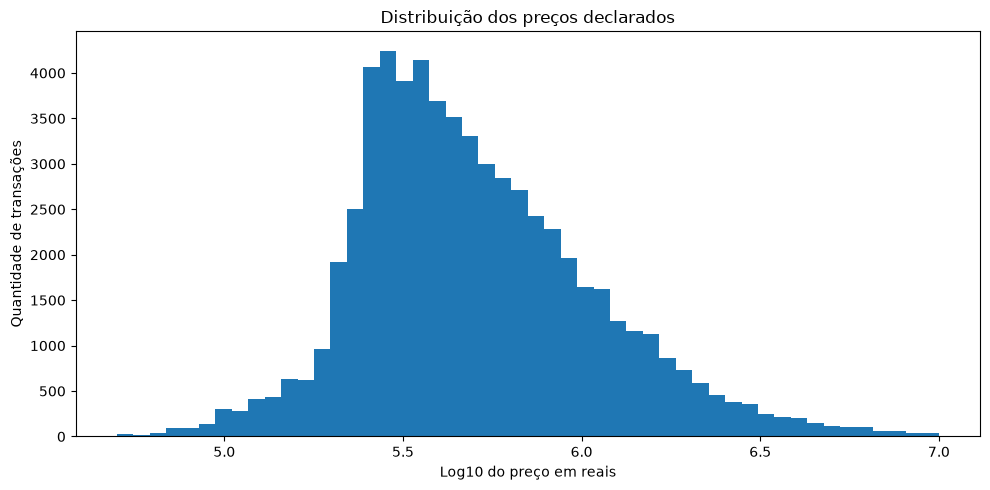

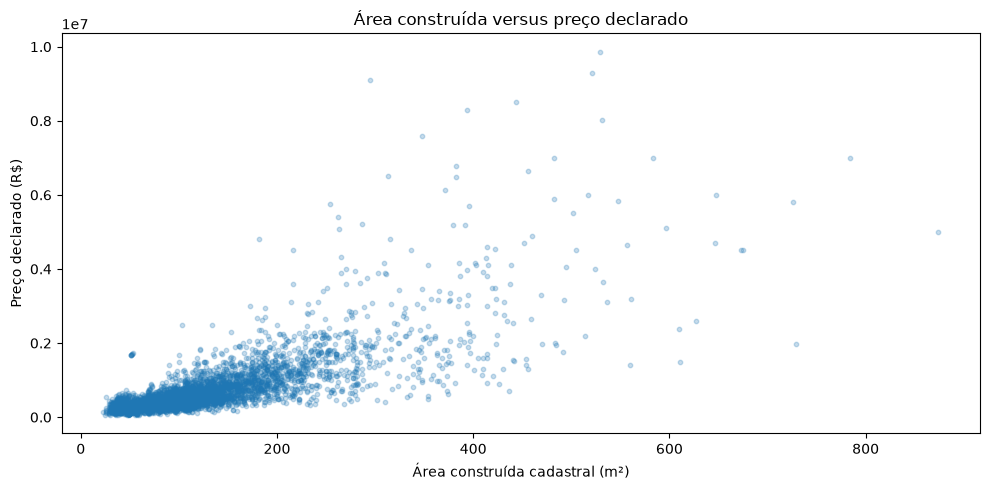


Análise da variável-alvo concluída: OK


In [21]:

# -------------------------------------------------
# AULA 03 — ANÁLISE DA VARIÁVEL-ALVO
# -------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

COL_PRECO = (
    "Valor de Transação (declarado pelo contribuinte)"
)
COL_AREA = "Área Construída (m2)"

print("ANÁLISE DA VARIÁVEL-ALVO")
print("=" * 65)

# -------------------------------------------------
# 1. PREPARAR OS DADOS
# -------------------------------------------------

analise_preco = base_enriquecida[
    [
        COL_PRECO,
        COL_AREA,
        "cep_3",
    ]
].copy()

analise_preco["preco"] = pd.to_numeric(
    analise_preco[COL_PRECO],
    errors="coerce",
)

analise_preco["area"] = pd.to_numeric(
    analise_preco[COL_AREA],
    errors="coerce",
)

assert analise_preco["preco"].notna().all()
assert (analise_preco["preco"] > 0).all()
assert (analise_preco["area"] > 0).all()

analise_preco["preco_m2_cadastral"] = (
    analise_preco["preco"]
    / analise_preco["area"]
)

# -------------------------------------------------
# 2. ESTATÍSTICAS DESCRITIVAS
# -------------------------------------------------

print("\n1. ESTATÍSTICAS DOS PREÇOS")
print("-" * 65)

estatisticas = analise_preco["preco"].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print(estatisticas.to_string())

print("\n2. ESTATÍSTICAS DO PREÇO POR M² CADASTRAL")
print("-" * 65)

print(
    analise_preco["preco_m2_cadastral"]
    .describe(
        percentiles=[
            0.10, 0.25, 0.50,
            0.75, 0.90, 0.95, 0.99,
        ]
    )
    .to_string()
)

# -------------------------------------------------
# 3. CORRELAÇÃO ENTRE ÁREA E PREÇO
# -------------------------------------------------

correlacao = analise_preco[
    ["area", "preco"]
].corr(method="spearman").iloc[0, 1]

print("\n3. RELAÇÃO ENTRE ÁREA E PREÇO")
print("-" * 65)
print(
    "Correlação de Spearman:",
    round(correlacao, 4),
)

# -------------------------------------------------
# 4. PREÇO MEDIANO POR PREFIXO DE CEP
# -------------------------------------------------

resumo_cep = (
    analise_preco
    .groupby("cep_3")
    .agg(
        quantidade=("preco", "size"),
        preco_mediano=("preco", "median"),
        preco_m2_mediano=(
            "preco_m2_cadastral",
            "median",
        ),
    )
    .reset_index()
)

print("\n4. DEZ PREFIXOS COM MAIOR PREÇO MEDIANO")
print("-" * 65)

print(
    resumo_cep.sort_values(
        "preco_mediano",
        ascending=False,
    )
    .head(10)
    .to_string(index=False)
)

# -------------------------------------------------
# 5. VISUALIZAÇÕES
# -------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    np.log10(analise_preco["preco"]),
    bins=50,
)

ax.set_title("Distribuição dos preços declarados")
ax.set_xlabel("Log10 do preço em reais")
ax.set_ylabel("Quantidade de transações")

plt.tight_layout()
plt.show()

# Amostra reproduzível para visualização
amostra = analise_preco.sample(
    n=min(5000, len(analise_preco)),
    random_state=42,
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    amostra["area"],
    amostra["preco"],
    alpha=0.25,
    s=10,
)

ax.set_title("Área construída versus preço declarado")
ax.set_xlabel("Área construída cadastral (m²)")
ax.set_ylabel("Preço declarado (R$)")

plt.tight_layout()
plt.show()

print("\nAnálise da variável-alvo concluída: OK")




# Aula 04 — Estratégia de Validação Temporal e Modelo Baseline

**Projeto:** Real Estate Price Prediction  
**Empresa fictícia:** Valoriza Imóveis Brasil  
**Sprint:** 0 — Entendimento do Negócio e Preparação dos Dados

---

## 1. Contexto da aula

Nas etapas anteriores, analisamos 62.121 transações imobiliárias elegíveis, referentes a apartamentos localizados no município de São Paulo, com datas de transação em 2025.

A análise exploratória identificou:

- Preço declarado mediano de R$ 450.000,00.
- Área construída cadastral mediana de aproximadamente 102 m².
- Correlação de Spearman de 0,7831 entre área construída e preço.
- 7.492 CEPs distintos, todos normalizados para oito dígitos.
- 50 grupos geográficos utilizando os três primeiros dígitos do CEP.
- Inconsistências e ausências significativas na variável Bairro.

Esses resultados permitem avançar para a definição de uma estratégia de avaliação preditiva.

## 2. Objetivo da aula

Definir uma separação temporal entre treinamento, validação e teste e preparar a implementação de um modelo de referência (baseline).

O objetivo é estabelecer um processo de avaliação reproduzível e reduzir o risco de vazamento de informações futuras.

## 3. Problema de Machine Learning

O problema será tratado inicialmente como uma tarefa de regressão supervisionada.

**Variável-alvo (y):**

Valor de Transação (declarado pelo contribuinte).

**Variáveis preditoras candidatas (X):**

- Área Construída (m2).
- Prefixo de três dígitos do CEP.
- Padrão (IPTU).
- Fração Ideal.
- Área do Terreno (m2).
- Testada (m).

A seleção definitiva dependerá da avaliação de qualidade, disponibilidade e desempenho preditivo.

## 4. Estratégia de validação temporal

A divisão inicial proposta é:

| Conjunto | Período de transação | Finalidade |
|---|---|---|
| Treinamento | Janeiro a setembro de 2025 | Ajustar o modelo |
| Validação | Outubro de 2025 | Comparar abordagens e parâmetros |
| Teste | Novembro e dezembro de 2025 | Avaliação final fora da amostra |

A divisão será realizada pela coluna Data de Transação, e não pelo mês da planilha de pagamento do ITBI.

A distribuição mensal será auditada antes da aprovação definitiva dessa estratégia.

## 5. Modelo baseline

O primeiro modelo de referência utilizará o preço mediano por metro quadrado cadastral observado exclusivamente no conjunto de treinamento.

A previsão será calculada pela multiplicação desse valor pela área construída cadastral do imóvel.

Esse procedimento permitirá avaliar se modelos mais sofisticados realmente oferecem melhorias sobre uma regra simples.

O preço por metro quadrado utilizado não corresponde necessariamente ao metro quadrado privativo, pois a área cadastral do IPTU pode incluir áreas comuns.

## 6. Métricas de avaliação

Serão consideradas inicialmente:

**MAE — Mean Absolute Error**

Média dos erros absolutos, expressa em reais.

**RMSE — Root Mean Squared Error**

Raiz do erro quadrático médio, que atribui maior peso a erros elevados.

**WAPE — Weighted Absolute Percentage Error**

Soma dos erros absolutos dividida pela soma dos preços reais, expressa em percentual.

As métricas serão calculadas separadamente para os conjuntos de validação e teste, respeitando o protocolo de avaliação.

## 7. Cuidados metodológicos

- Evitar vazamento de informações futuras.
- Não utilizar o preço declarado como variável preditora.
- Não utilizar o preço por metro quadrado da própria transação como variável preditora.
- Investigar possíveis repetições do mesmo imóvel entre os conjuntos temporais.
- Considerar o possível atraso entre a data da transação e o pagamento do ITBI.
- Reconhecer que os limites utilizados na filtragem de extremos são provisórios.
- Avaliar posteriormente a sensibilidade dos resultados aos critérios de exclusão.

## 8. Critérios de conclusão

A aula será considerada concluída quando:

1. A distribuição mensal das transações estiver auditada.
2. Os conjuntos temporais estiverem definidos e validados.
3. O baseline estiver implementado.
4. As métricas estiverem calculadas corretamente.
5. Os resultados e limitações estiverem documentados.

**Status:** Em andamento.


In [22]:

# -------------------------------------------------
# PROJETO 04 — REAL ESTATE PRICE PREDICTION
# SPRINT 0 — AULA 04
# ETAPA 01 — AUDITORIA TEMPORAL
# -------------------------------------------------

import pandas as pd

COL_PRECO = "Valor de Transação (declarado pelo contribuinte)"
COL_AREA = "Área Construída (m2)"

print("AUDITORIA TEMPORAL DAS TRANSAÇÕES")
print("=" * 65)

# 1. Preparar os dados

base_temporal = base_enriquecida.copy()

base_temporal["data_transacao"] = pd.to_datetime(
    base_temporal["Data de Transação"],
    errors="coerce",
)

assert base_temporal["data_transacao"].notna().all()
assert base_temporal["data_transacao"].dt.year.eq(2025).all()

# 2. Criar referência mensal

base_temporal["mes_transacao"] = (
    base_temporal["data_transacao"].dt.to_period("M")
)

# 3. Resumo mensal

resumo_mensal = (
    base_temporal
    .groupby("mes_transacao")
    .agg(
        transacoes=("data_transacao", "size"),
        preco_mediano=(COL_PRECO, "median"),
        area_mediana=(COL_AREA, "median"),
    )
    .reset_index()
)

print("\n1. DISTRIBUIÇÃO MENSAL")
print("-" * 65)
print(resumo_mensal.to_string(index=False))

print("\nTotal de transações:", len(base_temporal))

# 4. Separação temporal proposta

treino = base_temporal.loc[
    base_temporal["data_transacao"] < "2025-10-01"
].copy()

validacao = base_temporal.loc[
    (base_temporal["data_transacao"] >= "2025-10-01")
    & (base_temporal["data_transacao"] < "2025-11-01")
].copy()

teste = base_temporal.loc[
    base_temporal["data_transacao"] >= "2025-11-01"
].copy()

# 5. Conferir quantidades

print("\n2. DIVISÃO TEMPORAL PROPOSTA")
print("-" * 65)

for nome, dados in [
    ("Treinamento", treino),
    ("Validação", validacao),
    ("Teste", teste),
]:
    percentual = len(dados) / len(base_temporal) * 100

    print(
        f"{nome:12s}: {len(dados):6,d} registros "
        f"({percentual:.2f}%)"
    )

# 6. Verificar integridade

assert len(base_temporal) == 62121

assert (
    len(treino) + len(validacao) + len(teste)
    == len(base_temporal)
)

assert len(treino) > 0
assert len(validacao) > 0
assert len(teste) > 0

assert (
    treino["data_transacao"].max()
    < validacao["data_transacao"].min()
)

assert (
    validacao["data_transacao"].max()
    < teste["data_transacao"].min()
)

print("\nAuditoria temporal: OK")


AUDITORIA TEMPORAL DAS TRANSAÇÕES

1. DISTRIBUIÇÃO MENSAL
-----------------------------------------------------------------
mes_transacao  transacoes  preco_mediano  area_mediana
      2025-01        4456     465000.000         106.0
      2025-02        4934     448000.000         102.0
      2025-03        4817     458000.000         104.0
      2025-04        5308     450000.000         103.0
      2025-05        5576     455482.955         102.0
      2025-06        5200     427609.600          98.0
      2025-07        5229     445000.000         101.0
      2025-08        5282     450000.000         102.0
      2025-09        5423     450000.000         101.0
      2025-10        5791     450000.000         101.0
      2025-11        4820     455158.850         101.0
      2025-12        5285     440000.000         100.0

Total de transações: 62121

2. DIVISÃO TEMPORAL PROPOSTA
-----------------------------------------------------------------
Treinamento : 46,225 registros (74.41


## Aula 04 — Etapa 02: Implementação do Modelo Baseline

### 1. Objetivo

Construir um modelo de referência simples para prever o valor declarado de transações imobiliárias.

O baseline permitirá avaliar se os futuros modelos de Machine Learning apresentam ganhos reais de desempenho.

### 2. Estratégia adotada

Utilizaremos o preço mediano por metro quadrado cadastral calculado exclusivamente com as transações do conjunto de treinamento.

Para cada imóvel, a previsão será obtida multiplicando esse valor mediano pela área construída cadastral.

Essa abordagem incorpora o tamanho do imóvel, mas ainda não considera localização, padrão construtivo ou outras características.

### 3. Prevenção de vazamento de dados

O cálculo do preço mediano por metro quadrado utilizará somente os dados de treinamento, correspondentes às transações de janeiro a setembro de 2025.

Os preços reais de outubro de 2025 serão utilizados apenas para avaliar as previsões do baseline.

Os dados de teste, correspondentes a novembro e dezembro, permanecerão reservados para a avaliação final.

### 4. Métricas de avaliação

**MAE — Erro Absoluto Médio**

Representa a média das diferenças absolutas entre preços previstos e observados, expressa em reais.

**RMSE — Raiz do Erro Quadrático Médio**

Penaliza erros elevados com maior intensidade.

**WAPE — Erro Percentual Absoluto Ponderado**

Expressa a soma dos erros absolutos como percentual da soma dos preços observados.

### 5. Limitações

- O modelo não diferencia regiões da cidade.
- Imóveis de mesmo tamanho recebem previsões iguais.
- A área construída cadastral não equivale necessariamente à área privativa.
- O preço por metro quadrado cadastral pode variar substancialmente entre imóveis.
- O baseline não representa uma avaliação imobiliária profissional.

### 6. Critérios de validação

A etapa será considerada concluída quando:

1. O preço mediano por metro quadrado for calculado apenas no treinamento.
2. As previsões de validação forem geradas sem utilizar os preços reais como entrada.
3. MAE, RMSE e WAPE forem calculados.
4. Os resultados forem interpretados e documentados.

**Status:** Em andamento.


In [23]:

# -------------------------------------------------
# PROJETO 04 — REAL ESTATE PRICE PREDICTION
# SPRINT 0 — AULA 04
# ETAPA 02 — MODELO BASELINE
# -------------------------------------------------

import numpy as np
import pandas as pd

COL_PRECO = "Valor de Transação (declarado pelo contribuinte)"
COL_AREA = "Área Construída (m2)"

print("MODELO BASELINE — PREÇO MEDIANO POR M² CADASTRAL")
print("=" * 65)

# -------------------------------------------------
# 1. VALIDAR OS CONJUNTOS
# -------------------------------------------------

assert len(treino) == 46225
assert len(validacao) == 5791
assert len(teste) == 10105

for nome, dados in [
    ("Treino", treino),
    ("Validação", validacao),
]:
    assert dados[COL_PRECO].notna().all(), (
        f"Preços ausentes em {nome}"
    )

    assert (dados[COL_PRECO] > 0).all(), (
        f"Preços inválidos em {nome}"
    )

    assert (dados[COL_AREA] > 0).all(), (
        f"Áreas inválidas em {nome}"
    )

# -------------------------------------------------
# 2. AJUSTAR O BASELINE SOMENTE NO TREINAMENTO
# -------------------------------------------------

preco_m2_treino = (
    treino[COL_PRECO] / treino[COL_AREA]
)

mediana_preco_m2 = float(
    preco_m2_treino.median()
)

print("\n1. PARÂMETRO APRENDIDO NO TREINAMENTO")
print("-" * 65)

print(
    f"Preço mediano por m² cadastral: "
    f"R$ {mediana_preco_m2:,.2f}"
)

# -------------------------------------------------
# 3. GERAR PREVISÕES
# -------------------------------------------------

y_treino = treino[COL_PRECO].to_numpy(dtype=float)
y_validacao = validacao[COL_PRECO].to_numpy(dtype=float)

previsao_treino = (
    treino[COL_AREA].to_numpy(dtype=float)
    * mediana_preco_m2
)

previsao_validacao = (
    validacao[COL_AREA].to_numpy(dtype=float)
    * mediana_preco_m2
)

# -------------------------------------------------
# 4. DEFINIR MÉTRICAS
# -------------------------------------------------

def calcular_metricas(y_real, y_previsto):
    y_real = np.asarray(y_real, dtype=float)
    y_previsto = np.asarray(y_previsto, dtype=float)

    assert len(y_real) == len(y_previsto)
    assert np.isfinite(y_real).all()
    assert np.isfinite(y_previsto).all()

    erros = y_real - y_previsto

    mae = np.mean(np.abs(erros))
    rmse = np.sqrt(np.mean(erros ** 2))

    denominador = np.sum(np.abs(y_real))

    wape = (
        np.sum(np.abs(erros)) / denominador * 100
        if denominador > 0
        else np.nan
    )

    return {
        "MAE (R$)": mae,
        "RMSE (R$)": rmse,
        "WAPE (%)": wape,
    }

# -------------------------------------------------
# 5. AVALIAR TREINAMENTO E VALIDAÇÃO
# -------------------------------------------------

metricas_treino = calcular_metricas(
    y_treino,
    previsao_treino,
)

metricas_validacao = calcular_metricas(
    y_validacao,
    previsao_validacao,
)

resultados_baseline = pd.DataFrame([
    {
        "Conjunto": "Treinamento",
        **metricas_treino,
    },
    {
        "Conjunto": "Validação",
        **metricas_validacao,
    },
])

print("\n2. RESULTADOS DO BASELINE")
print("-" * 65)

print(
    resultados_baseline.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# -------------------------------------------------
# 6. VERIFICAÇÕES DE INTEGRIDADE
# -------------------------------------------------

assert mediana_preco_m2 > 0
assert np.isfinite(previsao_validacao).all()
assert (previsao_validacao > 0).all()
assert len(previsao_validacao) == len(validacao)

print("\nBaseline implementado e validado: OK")
print("Conjunto de teste preservado para avaliação final.")


MODELO BASELINE — PREÇO MEDIANO POR M² CADASTRAL

1. PARÂMETRO APRENDIDO NO TREINAMENTO
-----------------------------------------------------------------
Preço mediano por m² cadastral: R$ 4,901.96

2. RESULTADOS DO BASELINE
-----------------------------------------------------------------
   Conjunto   MAE (R$)  RMSE (R$)  WAPE (%)
Treinamento 264,153.14 560,165.00     37.37
  Validação 275,366.26 610,921.79     37.64

Baseline implementado e validado: OK
Conjunto de teste preservado para avaliação final.



## Aula 04 — Etapa 03: Diagnóstico dos Erros do Baseline

### 1. Objetivo

Investigar o comportamento dos erros do modelo baseline no conjunto de validação, identificando padrões de subestimação, superestimação e diferenças de desempenho entre grupos de imóveis.

### 2. Contexto

O baseline utiliza o preço mediano por metro quadrado cadastral do conjunto de treinamento para prever o valor declarado de cada transação.

Na validação, o modelo apresentou:

- MAE: R$ 275.366,26.
- RMSE: R$ 610.921,79.
- WAPE: 37,64%.

Embora seja uma referência simples, o modelo ainda apresenta erros expressivos.

### 3. Perguntas analíticas

Esta etapa busca responder:

1. O baseline tende a subestimar ou superestimar os preços?
2. Os erros aumentam em imóveis de maior valor?
3. A qualidade das previsões varia conforme a área construída?
4. Existem diferenças de desempenho entre os grupos geográficos representados por cep_3?

### 4. Indicadores utilizados

**Erro assinado**

Diferença entre o preço real e o preço previsto.

- Erro positivo: o modelo subestimou o preço.
- Erro negativo: o modelo superestimou o preço.

**Erro absoluto**

Magnitude do erro, independentemente de sua direção.

**MAE por grupo**

Média dos erros absolutos dentro de cada faixa ou grupo.

**WAPE por grupo**

Soma dos erros absolutos dividida pela soma dos preços reais do grupo.

### 5. Estratégia de análise

Serão realizadas:

- Análise da distribuição dos erros.
- Comparação de desempenho por faixas de área construída.
- Comparação por faixas de preço declarado.
- Identificação dos grupos cep_3 com maiores erros.
- Visualização dos erros em função do preço real.

As faixas de preço serão utilizadas apenas para diagnóstico, nunca como características disponíveis para gerar previsões.

### 6. Cuidados metodológicos

O diagnóstico utilizará exclusivamente o conjunto de validação.

O conjunto de teste permanecerá reservado.

As análises de grupos pequenos serão interpretadas com cautela, pois suas métricas podem apresentar elevada variabilidade.

### 7. Critérios de conclusão

A etapa estará concluída quando:

1. Os erros individuais forem calculados corretamente.
2. O viés médio de previsão for identificado.
3. As diferenças de desempenho entre faixas forem avaliadas.
4. Os resultados forem documentados.
5. As limitações do baseline estiverem claras.

**Status:** Em andamento.


DIAGNÓSTICO DOS ERROS DO BASELINE

1. DIAGNÓSTICO GERAL
----------------------------------------------------------------------
Erro médio assinado: R$ 121,414.15
Transações subestimadas: 3002
Transações superestimadas: 2786
Previsões exatas: 3

2. ERROS POR FAIXA DE ÁREA
----------------------------------------------------------------------
     faixa_area  quantidade  preco_mediano          mae  wape_pct
      Até 50 m²         781     255,000.00    99,409.12     37.04
      50–100 m²        2089     325,000.00   117,279.00     32.30
     100–150 m²        1521     550,000.00   202,141.83     33.03
     150–250 m²         950   1,066,475.00   406,806.51     34.74
Acima de 250 m²         450   2,115,382.50 1,284,639.45     47.19

3. ERROS POR FAIXA DE PREÇO REAL
----------------------------------------------------------------------
     faixa_preco  quantidade  preco_mediano          mae  wape_pct
  Até R$ 300 mil        1578     245,000.00   120,067.55     52.61
  R$ 300–500 mil      

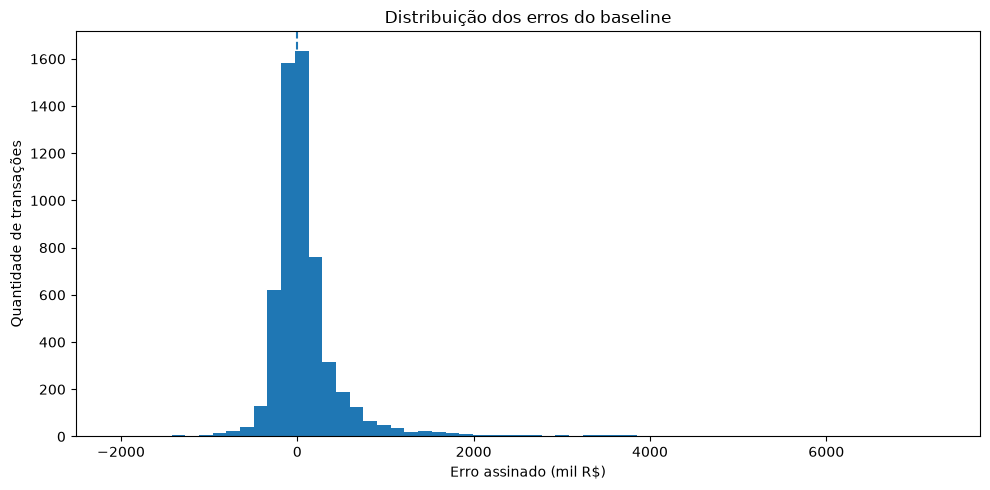

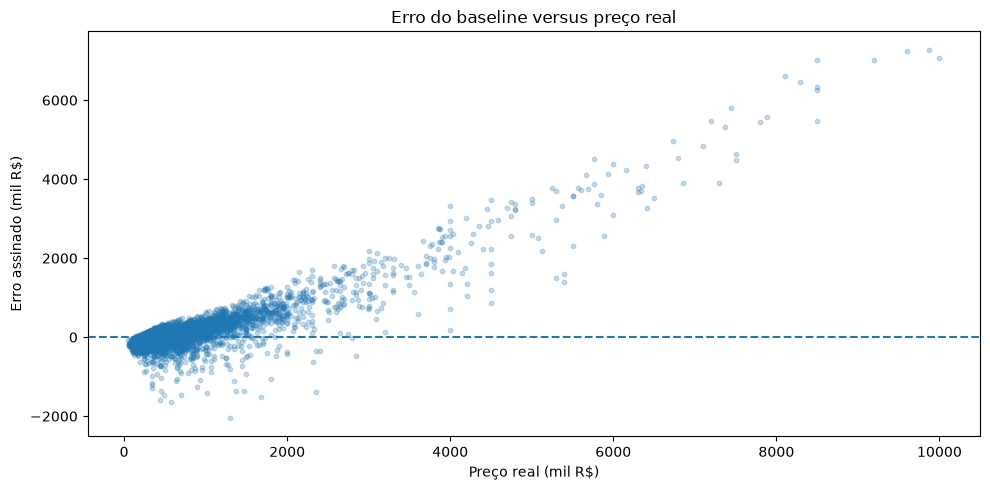


Diagnóstico dos erros: OK
Conjunto de teste preservado.


In [24]:

# -------------------------------------------------
# PROJETO 04 — REAL ESTATE PRICE PREDICTION
# SPRINT 0 — AULA 04
# ETAPA 03 — DIAGNÓSTICO DOS ERROS DO BASELINE
# -------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

COL_PRECO = "Valor de Transação (declarado pelo contribuinte)"
COL_AREA = "Área Construída (m2)"

print("DIAGNÓSTICO DOS ERROS DO BASELINE")
print("=" * 70)

# -------------------------------------------------
# 1. CONSTRUIR BASE DE DIAGNÓSTICO
# -------------------------------------------------

diagnostico = validacao[
    [COL_PRECO, COL_AREA, "cep_3"]
].copy()

diagnostico["preco_real"] = (
    diagnostico[COL_PRECO].astype(float)
)

diagnostico["preco_previsto"] = (
    np.asarray(previsao_validacao, dtype=float)
)

assert len(diagnostico) == len(previsao_validacao)

diagnostico["erro"] = (
    diagnostico["preco_real"]
    - diagnostico["preco_previsto"]
)

diagnostico["erro_absoluto"] = (
    diagnostico["erro"].abs()
)

# -------------------------------------------------
# 2. DIAGNÓSTICO GERAL
# -------------------------------------------------

print("\n1. DIAGNÓSTICO GERAL")
print("-" * 70)

erro_medio = diagnostico["erro"].mean()

print(f"Erro médio assinado: R$ {erro_medio:,.2f}")

print(
    "Transações subestimadas:",
    int((diagnostico["erro"] > 0).sum())
)

print(
    "Transações superestimadas:",
    int((diagnostico["erro"] < 0).sum())
)

print(
    "Previsões exatas:",
    int((diagnostico["erro"] == 0).sum())
)

# -------------------------------------------------
# 3. FUNÇÃO PARA MÉTRICAS POR GRUPO
# -------------------------------------------------

def resumo_erros_por_grupo(dados, coluna):
    resumo = (
        dados
        .groupby(coluna, observed=True)
        .agg(
            quantidade=("erro", "size"),
            preco_mediano=("preco_real", "median"),
            mae=("erro_absoluto", "mean"),
            soma_erros=("erro_absoluto", "sum"),
            soma_precos=("preco_real", "sum"),
        )
        .reset_index()
    )

    resumo["wape_pct"] = (
        resumo["soma_erros"]
        / resumo["soma_precos"]
        * 100
    )

    return resumo.drop(
        columns=["soma_erros", "soma_precos"]
    )

# -------------------------------------------------
# 4. ERROS POR FAIXA DE ÁREA
# -------------------------------------------------

diagnostico["faixa_area"] = pd.cut(
    diagnostico[COL_AREA],
    bins=[0, 50, 100, 150, 250, np.inf],
    labels=[
        "Até 50 m²",
        "50–100 m²",
        "100–150 m²",
        "150–250 m²",
        "Acima de 250 m²",
    ],
    include_lowest=True,
)

resumo_area = resumo_erros_por_grupo(
    diagnostico,
    "faixa_area",
)

print("\n2. ERROS POR FAIXA DE ÁREA")
print("-" * 70)

print(
    resumo_area.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# -------------------------------------------------
# 5. ERROS POR FAIXA DE PREÇO REAL
# -------------------------------------------------

diagnostico["faixa_preco"] = pd.cut(
    diagnostico["preco_real"],
    bins=[
        0,
        300000,
        500000,
        1000000,
        2000000,
        np.inf,
    ],
    labels=[
        "Até R$ 300 mil",
        "R$ 300–500 mil",
        "R$ 500 mil–1 mi",
        "R$ 1–2 mi",
        "Acima de R$ 2 mi",
    ],
    include_lowest=True,
)

resumo_preco = resumo_erros_por_grupo(
    diagnostico,
    "faixa_preco",
)

print("\n3. ERROS POR FAIXA DE PREÇO REAL")
print("-" * 70)

print(
    resumo_preco.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# -------------------------------------------------
# 6. ERROS POR PREFIXO DE CEP
# -------------------------------------------------

resumo_localizacao = resumo_erros_por_grupo(
    diagnostico,
    "cep_3",
)

# Considerar apenas grupos com pelo menos
# 30 transações na validação
resumo_localizacao = resumo_localizacao.loc[
    resumo_localizacao["quantidade"] >= 30
]

print("\n4. DEZ PREFIXOS COM MAIOR MAE")
print("-" * 70)

print(
    resumo_localizacao
    .sort_values("mae", ascending=False)
    .head(10)
    .to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# -------------------------------------------------
# 7. VISUALIZAÇÕES
# -------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    diagnostico["erro"] / 1000,
    bins=60,
)

ax.axvline(0, linestyle="--")

ax.set_title("Distribuição dos erros do baseline")
ax.set_xlabel("Erro assinado (mil R$)")
ax.set_ylabel("Quantidade de transações")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    diagnostico["preco_real"] / 1000,
    diagnostico["erro"] / 1000,
    alpha=0.25,
    s=10,
)

ax.axhline(0, linestyle="--")

ax.set_title("Erro do baseline versus preço real")
ax.set_xlabel("Preço real (mil R$)")
ax.set_ylabel("Erro assinado (mil R$)")

plt.tight_layout()
plt.show()

# -------------------------------------------------
# 8. VERIFICAÇÕES FINAIS
# -------------------------------------------------

assert len(diagnostico) == len(validacao)

assert np.isclose(
    diagnostico["erro_absoluto"].mean(),
    metricas_validacao["MAE (R$)"],
)

print("\nDiagnóstico dos erros: OK")
print("Conjunto de teste preservado.")



## Aula 04 — Etapa 04: Auditoria de Sobreposição entre Conjuntos

### 1. Objetivo

Investigar se os mesmos imóveis ou identificadores cadastrais aparecem em mais de um conjunto temporal.

### 2. Motivação

A divisão temporal separou as transações de acordo com a Data de Transação:

- Treinamento: janeiro a setembro de 2025.
- Validação: outubro de 2025.
- Teste: novembro e dezembro de 2025.

Embora essa estratégia preserve a ordem cronológica, ela não impede que um mesmo imóvel apareça em períodos diferentes.

### 3. Riscos metodológicos

A presença de um mesmo imóvel em diferentes períodos pode:

- Produzir dependência entre observações.
- Facilitar a memorização de características específicas do imóvel.
- Superestimar o desempenho de modelos que utilizem identificadores ou atributos muito específicos.

Uma repetição cadastral não significa necessariamente duplicidade indevida. Um imóvel pode ter mais de uma transação, e identificadores cadastrais também precisam ser interpretados com cautela.

### 4. Identificadores investigados

Serão analisados:

- N° do Cadastro (SQL).
- Matrícula do Imóvel.
- Combinação entre SQL e matrícula.

Valores ausentes ou vazios serão desconsiderados na identificação de sobreposições.

### 5. Critério de conclusão

A etapa será concluída quando a sobreposição entre treinamento, validação e teste estiver quantificada e seus possíveis efeitos metodológicos forem discutidos.

O conjunto de teste não será utilizado para avaliar previsões ou escolher parâmetros.

**Status:** Em andamento.


In [25]:

# -------------------------------------------------
# PROJETO 04 — REAL ESTATE PRICE PREDICTION
# SPRINT 0 — AULA 04
# ETAPA 04 — AUDITORIA DE SOBREPOSIÇÃO
# -------------------------------------------------

import pandas as pd

print("AUDITORIA DE SOBREPOSIÇÃO ENTRE CONJUNTOS")
print("=" * 70)

COL_SQL = "N° do Cadastro (SQL)"
COL_MATRICULA = "Matrícula do Imóvel"

conjuntos = {
    "Treinamento": treino,
    "Validação": validacao,
    "Teste": teste,
}

# -------------------------------------------------
# 1. NORMALIZAR IDENTIFICADORES
# -------------------------------------------------

def preparar_identificadores(dados):
    resultado = dados[
        [COL_SQL, COL_MATRICULA]
    ].copy()

    for coluna in [COL_SQL, COL_MATRICULA]:
        resultado[coluna] = (
            resultado[coluna]
            .astype("string")
            .str.strip()
            .str.replace(r"\.0$", "", regex=True)
            .replace("", pd.NA)
        )

    return resultado

identificadores = {
    nome: preparar_identificadores(dados)
    for nome, dados in conjuntos.items()
}

# -------------------------------------------------
# 2. FUNÇÃO DE COMPARAÇÃO
# -------------------------------------------------

def contar_sobreposicao(origem, destino, colunas):

    a = identificadores[origem][colunas].dropna()
    b = identificadores[destino][colunas].dropna()

    # Identificadores presentes na origem
    chaves_origem = set(
        a.itertuples(index=False, name=None)
    )

    # Comparar linhas do destino
    chaves_destino = list(
        b.itertuples(index=False, name=None)
    )

    ocorrencias = sum(
        chave in chaves_origem
        for chave in chaves_destino
    )

    return {
        "Origem": origem,
        "Destino": destino,
        "Identificador": " + ".join(colunas),
        "Registros sobrepostos": ocorrencias,
        "Registros com chave no destino": len(b),
        "Percentual (%)": (
            ocorrencias / len(b) * 100
            if len(b) > 0
            else 0
        ),
    }

# -------------------------------------------------
# 3. EXECUTAR AS COMPARAÇÕES
# -------------------------------------------------

comparacoes = [
    ("Treinamento", "Validação"),
    ("Treinamento", "Teste"),
    ("Validação", "Teste"),
]

chaves = [
    [COL_SQL],
    [COL_MATRICULA],
    [COL_SQL, COL_MATRICULA],
]

resultados = []

for origem, destino in comparacoes:
    for colunas in chaves:
        resultados.append(
            contar_sobreposicao(
                origem,
                destino,
                colunas,
            )
        )

relatorio_sobreposicao = pd.DataFrame(
    resultados
)

print("\n1. SOBREPOSIÇÃO DE IDENTIFICADORES")
print("-" * 70)

print(
    relatorio_sobreposicao.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# -------------------------------------------------
# 4. VERIFICAR AUSÊNCIA DE IDENTIFICADORES
# -------------------------------------------------

print("\n2. IDENTIFICADORES AUSENTES")
print("-" * 70)

for nome, dados in identificadores.items():
    print(f"\n{nome}: {len(dados):,} registros")

    for coluna in [COL_SQL, COL_MATRICULA]:
        print(
            f"  {coluna}: "
            f"{dados[coluna].isna().sum():,} ausentes"
        )

# -------------------------------------------------
# 5. CONFERÊNCIAS
# -------------------------------------------------

assert len(treino) == 46225
assert len(validacao) == 5791
assert len(teste) == 10105

assert len(relatorio_sobreposicao) == 9

print("\nAuditoria de sobreposição: OK")
print("Nenhum conjunto foi alterado.")


AUDITORIA DE SOBREPOSIÇÃO ENTRE CONJUNTOS

1. SOBREPOSIÇÃO DE IDENTIFICADORES
----------------------------------------------------------------------
     Origem   Destino                              Identificador  Registros sobrepostos  Registros com chave no destino  Percentual (%)
Treinamento Validação                       N° do Cadastro (SQL)                    138                            5791            2.38
Treinamento Validação                        Matrícula do Imóvel                    762                            5791           13.16
Treinamento Validação N° do Cadastro (SQL) + Matrícula do Imóvel                    131                            5791            2.26
Treinamento     Teste                       N° do Cadastro (SQL)                    230                           10105            2.28
Treinamento     Teste                        Matrícula do Imóvel                   1310                           10105           12.96
Treinamento     Teste N° do Cadastr


## Aula 04 — Etapa 05: Investigação de Sobreposição e Risco de Vazamento

### 1. Contexto

Na etapa anterior, identificamos registros com identificadores cadastrais repetidos entre os conjuntos temporais.

A combinação entre N° do Cadastro (SQL) e Matrícula do Imóvel apareceu em:

- 131 registros da validação também identificados no treinamento.
- 221 registros do teste também identificados no treinamento.
- 43 registros do teste também identificados na validação.

A existência de identificadores repetidos não significa necessariamente que as transações sejam duplicadas ou inválidas.

### 2. Objetivo

Investigar os registros sobrepostos entre treinamento e validação, identificando diferenças de datas, valores e características dos imóveis.

O objetivo é avaliar o risco de dependência entre observações e fundamentar a estratégia de validação dos modelos preditivos.

### 3. Questões de investigação

1. Quantos imóveis distintos apresentam identificadores repetidos?
2. As transações possuem datas diferentes?
3. Os valores declarados são iguais ou diferentes?
4. Qual é o intervalo temporal entre as transações?
5. Existem indícios de registros idênticos em períodos diferentes?

### 4. Estratégia metodológica

A análise utilizará exclusivamente os conjuntos de treinamento e validação.

Serão comparados:

- N° do Cadastro (SQL).
- Matrícula do Imóvel.
- Data de Transação.
- Valor de Transação (declarado pelo contribuinte).
- Área Construída (m2).

Para cada registro sobreposto na validação, será selecionada a transação mais recente do treinamento com a mesma combinação de identificadores.

Essa seleção será utilizada apenas para diagnóstico, sem alterar as bases originais.

### 5. Critérios de avaliação

Os registros serão classificados conforme:

- Igualdade ou diferença entre os preços declarados.
- Igualdade ou diferença entre as áreas cadastrais.
- Intervalo entre as datas das transações.
- Existência de transações repetidas em períodos distintos.

A análise não será suficiente, isoladamente, para comprovar a identidade jurídica de um imóvel ou a validade de uma transação.

### 6. Prevenção de vazamento

O conjunto de teste permanecerá reservado.

Os resultados serão utilizados para decidir se a validação temporal original deve ser complementada por controles de sobreposição de identificadores.

### 7. Critérios de conclusão

A etapa será concluída quando:

1. Os registros sobrepostos estiverem identificados.
2. As diferenças entre transações forem quantificadas.
3. Os possíveis riscos de vazamento estiverem documentados.
4. A estratégia de validação puder ser fundamentada.

**Status:** Em andamento.


In [26]:

# -------------------------------------------------
# PROJETO 04 — REAL ESTATE PRICE PREDICTION
# SPRINT 0 — AULA 04
# ETAPA 05 — INVESTIGAÇÃO DE SOBREPOSIÇÃO
# -------------------------------------------------

import pandas as pd
import numpy as np

COL_SQL = "N° do Cadastro (SQL)"
COL_MATRICULA = "Matrícula do Imóvel"
COL_PRECO = "Valor de Transação (declarado pelo contribuinte)"
COL_AREA = "Área Construída (m2)"
COL_DATA = "Data de Transação"

print("INVESTIGAÇÃO DE SOBREPOSIÇÃO — TREINO × VALIDAÇÃO")
print("=" * 70)

# -------------------------------------------------
# 1. PREPARAR CÓPIAS DOS CONJUNTOS
# -------------------------------------------------

colunas = [
    COL_SQL,
    COL_MATRICULA,
    COL_PRECO,
    COL_AREA,
    COL_DATA,
]

treino_investigacao = treino[colunas].copy()
validacao_investigacao = validacao[colunas].copy()

for dados in [
    treino_investigacao,
    validacao_investigacao,
]:
    dados["data_normalizada"] = pd.to_datetime(
        dados[COL_DATA],
        errors="coerce",
    )

    dados["preco_normalizado"] = pd.to_numeric(
        dados[COL_PRECO],
        errors="coerce",
    )

    dados["area_normalizada"] = pd.to_numeric(
        dados[COL_AREA],
        errors="coerce",
    )

    for coluna in [COL_SQL, COL_MATRICULA]:
        dados[coluna] = (
            dados[coluna]
            .astype("string")
            .str.strip()
            .str.replace(r"\.0$", "", regex=True)
            .replace("", pd.NA)
        )

# -------------------------------------------------
# 2. VALIDAR IDENTIFICADORES E DATAS
# -------------------------------------------------

assert treino_investigacao[
    [COL_SQL, COL_MATRICULA, "data_normalizada"]
].notna().all().all()

assert validacao_investigacao[
    [COL_SQL, COL_MATRICULA, "data_normalizada"]
].notna().all().all()

# -------------------------------------------------
# 3. IDENTIFICAR REGISTROS SOBREPOSTOS
# -------------------------------------------------

chaves = [COL_SQL, COL_MATRICULA]

# Transação mais recente de cada chave no treinamento
treino_ultimo = (
    treino_investigacao
    .sort_values("data_normalizada")
    .drop_duplicates(
        subset=chaves,
        keep="last",
    )
)

# Associar apenas registros com a mesma chave
sobrepostos = validacao_investigacao.merge(
    treino_ultimo[
        chaves
        + [
            "data_normalizada",
            "preco_normalizado",
            "area_normalizada",
        ]
    ],
    on=chaves,
    how="inner",
    suffixes=("_validacao", "_treino"),
    validate="many_to_one",
)

print("\n1. QUANTIDADE DE SOBREPOSIÇÕES")
print("-" * 70)

print(
    "Registros sobrepostos na validação:",
    len(sobrepostos),
)

print(
    "Combinações SQL + matrícula distintas:",
    sobrepostos[chaves].drop_duplicates().shape[0],
)

assert len(sobrepostos) == 131, (
    "A quantidade divergiu da auditoria anterior."
)

# -------------------------------------------------
# 4. COMPARAR AS TRANSAÇÕES
# -------------------------------------------------

sobrepostos["intervalo_dias"] = (
    sobrepostos["data_normalizada_validacao"]
    - sobrepostos["data_normalizada_treino"]
).dt.days

sobrepostos["preco_igual"] = np.isclose(
    sobrepostos["preco_normalizado_validacao"],
    sobrepostos["preco_normalizado_treino"],
    rtol=0,
    atol=0.01,
)

sobrepostos["area_igual"] = np.isclose(
    sobrepostos["area_normalizada_validacao"],
    sobrepostos["area_normalizada_treino"],
    rtol=0,
    atol=0.001,
)

sobrepostos["variacao_preco_pct"] = (
    (
        sobrepostos["preco_normalizado_validacao"]
        / sobrepostos["preco_normalizado_treino"]
    ) - 1
) * 100

# -------------------------------------------------
# 5. RESUMO DAS COMPARAÇÕES
# -------------------------------------------------

print("\n2. COMPARAÇÃO DAS TRANSAÇÕES")
print("-" * 70)

print(
    "Preços iguais:",
    int(sobrepostos["preco_igual"].sum()),
)

print(
    "Preços diferentes:",
    int((~sobrepostos["preco_igual"]).sum()),
)

print(
    "Áreas iguais:",
    int(sobrepostos["area_igual"].sum()),
)

print(
    "Áreas diferentes:",
    int((~sobrepostos["area_igual"]).sum()),
)

print(
    "Intervalos positivos:",
    int((sobrepostos["intervalo_dias"] > 0).sum()),
)

print(
    "Intervalos não positivos:",
    int((sobrepostos["intervalo_dias"] <= 0).sum()),
)

print("\n3. INTERVALO ENTRE TRANSAÇÕES")
print("-" * 70)

print(
    sobrepostos["intervalo_dias"]
    .describe()
    .to_string()
)

print("\n4. VARIAÇÃO PERCENTUAL DOS PREÇOS")
print("-" * 70)

print(
    sobrepostos["variacao_preco_pct"]
    .replace([np.inf, -np.inf], np.nan)
    .describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
    .to_string()
)

# -------------------------------------------------
# 6. VERIFICAR TRANSAÇÕES POTENCIALMENTE IDÊNTICAS
# -------------------------------------------------

possivelmente_identicas = sobrepostos.loc[
    sobrepostos["preco_igual"]
    & sobrepostos["area_igual"]
    & (
        sobrepostos["data_normalizada_validacao"]
        == sobrepostos["data_normalizada_treino"]
    )
]

print("\n5. POSSÍVEIS TRANSAÇÕES IDÊNTICAS")
print("-" * 70)

print(
    "Mesma chave, data, preço e área:",
    len(possivelmente_identicas),
)

# -------------------------------------------------
# 7. CONFERÊNCIAS
# -------------------------------------------------

assert (
    sobrepostos["intervalo_dias"] > 0
).all(), (
    "Foram encontradas datas fora da ordem temporal."
)

print("\nInvestigação de sobreposição: OK")
print("Treino, validação e teste não foram alterados.")


INVESTIGAÇÃO DE SOBREPOSIÇÃO — TREINO × VALIDAÇÃO

1. QUANTIDADE DE SOBREPOSIÇÕES
----------------------------------------------------------------------
Registros sobrepostos na validação: 131
Combinações SQL + matrícula distintas: 131

2. COMPARAÇÃO DAS TRANSAÇÕES
----------------------------------------------------------------------
Preços iguais: 9
Preços diferentes: 122
Áreas iguais: 131
Áreas diferentes: 0
Intervalos positivos: 131
Intervalos não positivos: 0

3. INTERVALO ENTRE TRANSAÇÕES
----------------------------------------------------------------------
count    131.000000
mean     140.755725
std       78.618954
min       20.000000
25%       68.000000
50%      121.000000
75%      205.000000
max      292.000000

4. VARIAÇÃO PERCENTUAL DOS PREÇOS
----------------------------------------------------------------------
count    131.000000
mean      45.397170
std       61.933934
min      -42.688172
10%       -0.871460
25%        9.055848
50%       32.314291
75%       61.669912
90%


## Aula 04 — Etapa 06: Protocolo de Validação e Análise de Sensibilidade

### 1. Objetivo

Definir o protocolo de avaliação dos modelos de regressão, considerando a ordem temporal das transações e a possível dependência entre registros associados aos mesmos identificadores cadastrais.

### 2. Resultados da investigação anterior

Foram identificados 131 registros da validação com combinações SQL + matrícula também presentes no treinamento.

Entre esses registros:

- 122 apresentaram preços diferentes.
- 9 apresentaram preços iguais.
- Todos apresentaram áreas iguais.
- Todos apresentaram datas posteriores.
- O intervalo mediano foi de 121 dias.
- Não foram identificados pares com a mesma chave, data, preço e área.

Esses resultados não comprovam duplicação indevida nem permitem descartar a possibilidade de dependência entre observações.

### 3. Protocolo principal

A avaliação principal utilizará a divisão temporal previamente estabelecida:

- Treinamento: janeiro a setembro de 2025.
- Validação: outubro de 2025.
- Teste: novembro e dezembro de 2025.

A seleção dos modelos será realizada exclusivamente com informações do treinamento e da validação.

O conjunto de teste permanecerá reservado.

### 4. Análise de sensibilidade

Além da validação completa, será calculado o desempenho em dois subconjuntos:

**Imóveis não observados anteriormente**

Registros da validação cujas combinações SQL + matrícula não aparecem no treinamento.

**Identificadores já observados**

Registros da validação cujas combinações SQL + matrícula aparecem no treinamento.

A comparação permitirá investigar se o desempenho varia conforme a presença anterior dos identificadores.

### 5. Métricas

Serão utilizadas:

- MAE: erro absoluto médio em reais.
- RMSE: raiz do erro quadrático médio em reais.
- WAPE: erro percentual absoluto ponderado.

O desempenho do subconjunto de identificadores repetidos será interpretado com cautela devido ao seu tamanho reduzido.

### 6. Regras de prevenção de vazamento

- Não utilizar SQL ou matrícula como variáveis preditoras.
- Não utilizar o preço real ou o preço por metro quadrado da própria transação como entrada do modelo.
- Ajustar transformações e codificações somente no treinamento.
- Utilizar a validação para comparar modelos.
- Reservar o teste para a avaliação final.
- Não excluir automaticamente transações com identificadores repetidos.

### 7. Critério de conclusão

A etapa será concluída quando os subconjuntos estiverem identificados e o baseline tiver sido avaliado separadamente em cada grupo.

**Status:** Em andamento.


In [27]:

# -------------------------------------------------
# PROJETO 04 — REAL ESTATE PRICE PREDICTION
# SPRINT 0 — AULA 04
# ETAPA 06 — PROTOCOLO DE VALIDAÇÃO
# -------------------------------------------------

import numpy as np
import pandas as pd

COL_SQL = "N° do Cadastro (SQL)"
COL_MATRICULA = "Matrícula do Imóvel"
COL_PRECO = "Valor de Transação (declarado pelo contribuinte)"

print("PROTOCOLO DE VALIDAÇÃO — ANÁLISE DE SENSIBILIDADE")
print("=" * 70)

# -------------------------------------------------
# 1. PREPARAR IDENTIFICADORES
# -------------------------------------------------

def criar_chaves(dados):
    resultado = dados[
        [COL_SQL, COL_MATRICULA]
    ].copy()

    for coluna in [COL_SQL, COL_MATRICULA]:
        resultado[coluna] = (
            resultado[coluna]
            .astype("string")
            .str.strip()
            .str.replace(r"\.0$", "", regex=True)
            .replace("", pd.NA)
        )

    return resultado

chaves_treino = criar_chaves(treino)
chaves_validacao = criar_chaves(validacao)

assert chaves_treino.notna().all().all()
assert chaves_validacao.notna().all().all()

# -------------------------------------------------
# 2. IDENTIFICAR IMÓVEIS JÁ OBSERVADOS
# -------------------------------------------------

conjunto_chaves_treino = set(
    chaves_treino.itertuples(
        index=False,
        name=None,
    )
)

mascara_repetidos = np.array([
    chave in conjunto_chaves_treino
    for chave in chaves_validacao.itertuples(
        index=False,
        name=None,
    )
])

assert len(mascara_repetidos) == len(validacao)
assert int(mascara_repetidos.sum()) == 131

# -------------------------------------------------
# 3. PREPARAR PREVISÕES E VALORES REAIS
# -------------------------------------------------

y_real = validacao[COL_PRECO].to_numpy(
    dtype=float
)

y_previsto = np.asarray(
    previsao_validacao,
    dtype=float,
)

assert len(y_real) == len(y_previsto)

# -------------------------------------------------
# 4. FUNÇÃO DE AVALIAÇÃO
# -------------------------------------------------

def avaliar_subconjunto(nome, mascara):
    real = y_real[mascara]
    previsto = y_previsto[mascara]

    erros = real - previsto

    return {
        "Conjunto": nome,
        "Registros": len(real),
        "MAE (R$)": np.mean(np.abs(erros)),
        "RMSE (R$)": np.sqrt(
            np.mean(erros ** 2)
        ),
        "WAPE (%)": (
            np.sum(np.abs(erros))
            / np.sum(np.abs(real))
            * 100
        ),
    }

# -------------------------------------------------
# 5. AVALIAR GRUPOS
# -------------------------------------------------

resultados_sensibilidade = pd.DataFrame([
    avaliar_subconjunto(
        "Validação completa",
        np.ones(len(validacao), dtype=bool),
    ),
    avaliar_subconjunto(
        "Identificadores novos",
        ~mascara_repetidos,
    ),
    avaliar_subconjunto(
        "Identificadores repetidos",
        mascara_repetidos,
    ),
])

print("\nRESULTADOS POR SUBCONJUNTO")
print("-" * 70)

print(
    resultados_sensibilidade.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# -------------------------------------------------
# 6. CONFERÊNCIAS
# -------------------------------------------------

assert (
    (~mascara_repetidos).sum()
    + mascara_repetidos.sum()
    == len(validacao)
)

assert np.isclose(
    resultados_sensibilidade.iloc[0]["MAE (R$)"],
    metricas_validacao["MAE (R$)"],
)

print("\nAnálise de sensibilidade: OK")
print("Conjunto de teste preservado.")


PROTOCOLO DE VALIDAÇÃO — ANÁLISE DE SENSIBILIDADE

RESULTADOS POR SUBCONJUNTO
----------------------------------------------------------------------
                 Conjunto  Registros   MAE (R$)  RMSE (R$)  WAPE (%)
       Validação completa       5791 275,366.26 610,921.79     37.64
    Identificadores novos       5660 274,823.14 612,554.80     37.66
Identificadores repetidos        131 298,832.56 535,632.32     36.67

Análise de sensibilidade: OK
Conjunto de teste preservado.



## Aula 04 — Etapa 07: Primeiro Modelo Supervisionado — Regressão Ridge

### 1. Objetivo

Construir o primeiro modelo supervisionado para estimar o valor declarado de transações de apartamentos residenciais em São Paulo.

O modelo será comparado ao baseline previamente estabelecido.

### 2. Algoritmo

Será utilizada a Regressão Ridge, uma regressão linear com regularização L2.

A regularização reduz a sensibilidade dos coeficientes a correlações entre variáveis, embora não elimine todos os problemas de modelagem.

### 3. Variáveis preditoras

**Numéricas:**
- Área Construída (m2).
- Fração Ideal.

**Categóricas:**
- Padrão (IPTU).
- Prefixo de três dígitos do CEP.

A área construída corresponde à informação cadastral do IPTU e não deve ser interpretada automaticamente como área privativa.

### 4. Pré-processamento

Será utilizado um Pipeline do Scikit-learn com:

- Imputação pela mediana para variáveis numéricas.
- Padronização das variáveis numéricas.
- Imputação pela categoria mais frequente para variáveis categóricas.
- One-Hot Encoding para categorias.
- Regressão Ridge.

Todas as transformações serão ajustadas exclusivamente com dados de treinamento.

### 5. Estratégia de validação

Treinamento: janeiro a setembro de 2025.

Validação: outubro de 2025.

Teste: novembro e dezembro de 2025, reservado.

### 6. Métricas

- MAE: erro absoluto médio.
- RMSE: raiz do erro quadrático médio.
- WAPE: erro percentual absoluto ponderado.

### 7. Critério de avaliação

O desempenho será comparado ao baseline na validação temporal.

Também serão avaliados separadamente os registros com identificadores novos e repetidos.

A etapa não utilizará dados do conjunto de teste.

**Status:** Em andamento.


In [29]:

# ------------------------------------------------------------
# PROJETO 04 — REAL ESTATE PRICE PREDICTION
# SPRINT 0 — AULA 04
# ETAPA 07 — PRIMEIRO MODELO SUPERVISIONADO: RIDGE
# ------------------------------------------------------------

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("PRIMEIRO MODELO SUPERVISIONADO — REGRESSÃO RIDGE")
print("=" * 70)

# ------------------------------------------------------------
# 1. DEFINIÇÕES
# ------------------------------------------------------------

COL_PRECO = "Valor de Transação (declarado pelo contribuinte)"
COL_AREA = "Área Construída (m2)"
COL_FRACAO = "Fração Ideal"
COL_PADRAO = "Padrão (IPTU)"
COL_CEP = "cep_3"

variaveis_numericas = [
    COL_AREA,
    COL_FRACAO,
]

variaveis_categoricas = [
    COL_PADRAO,
    COL_CEP,
]

variaveis_modelo = (
    variaveis_numericas + variaveis_categoricas
)

# ------------------------------------------------------------
# 2. PREPARAR DADOS
# ------------------------------------------------------------

def preparar_atributos(dados):
    X = dados.copy()

    # Recuperar o prefixo do CEP, se ainda não estiver
    # presente no conjunto temporal.
    if COL_CEP not in X.columns:
        if "cep_normalizado" in X.columns:
            cep = X["cep_normalizado"].astype("string")
        else:
            cep = (
                X["CEP"]
                .astype("string")
                .str.strip()
                .str.replace(r"\.0$", "", regex=True)
                .str.replace(r"\D", "", regex=True)
                .str.zfill(8)
            )

        X[COL_CEP] = cep.str[:3]

    X = X[variaveis_modelo].copy()

    for coluna in variaveis_numericas:
        X[coluna] = pd.to_numeric(
            X[coluna],
            errors="coerce",
        )

    for coluna in variaveis_categoricas:
        X[coluna] = (
            X[coluna]
            .astype("string")
            .str.strip()
            .replace("", pd.NA)
            .astype("object")
        )

        X[coluna] = X[coluna].where(
            pd.notna(X[coluna]),
            np.nan,
        )

    return X


X_treino = preparar_atributos(treino)
X_validacao = preparar_atributos(validacao)

y_treino = pd.to_numeric(
    treino[COL_PRECO],
    errors="raise",
).to_numpy(dtype=float)

y_validacao = pd.to_numeric(
    validacao[COL_PRECO],
    errors="raise",
).to_numpy(dtype=float)

assert np.isfinite(y_treino).all()
assert np.isfinite(y_validacao).all()

assert (y_treino > 0).all()
assert (y_validacao > 0).all()

assert len(X_treino) == len(y_treino)
assert len(X_validacao) == len(y_validacao)

print("\n1. DIMENSÕES DOS CONJUNTOS")
print("-" * 70)

print("Treinamento:", X_treino.shape)
print("Validação:", X_validacao.shape)

print("\nVariáveis utilizadas:")
for coluna in variaveis_modelo:
    print(" -", coluna)

# ------------------------------------------------------------
# 3. PIPELINE DE PRÉ-PROCESSAMENTO
# ------------------------------------------------------------

pipeline_numerico = Pipeline([
    (
        "imputador",
        SimpleImputer(strategy="median"),
    ),
    (
        "padronizador",
        StandardScaler(),
    ),
])

pipeline_categorico = Pipeline([
    (
        "imputador",
        SimpleImputer(strategy="most_frequent"),
    ),
    (
        "codificador",
        OneHotEncoder(
            handle_unknown="ignore",
        ),
    ),
])

preprocessador = ColumnTransformer([
    (
        "numericas",
        pipeline_numerico,
        variaveis_numericas,
    ),
    (
        "categoricas",
        pipeline_categorico,
        variaveis_categoricas,
    ),
])

# ------------------------------------------------------------
# 4. MODELO RIDGE
# ------------------------------------------------------------

modelo_ridge = Pipeline([
    (
        "preprocessamento",
        preprocessador,
    ),
    (
        "regressor",
        Ridge(alpha=100.0),
    ),
])

print("\n2. TREINAMENTO")
print("-" * 70)

modelo_ridge.fit(X_treino, y_treino)

print("Modelo Ridge treinado com sucesso.")

# ------------------------------------------------------------
# 5. PREVISÕES
# ------------------------------------------------------------

previsao_ridge_treino = modelo_ridge.predict(
    X_treino
)

previsao_ridge_validacao = modelo_ridge.predict(
    X_validacao
)

# Preços negativos não são economicamente válidos.
# Para a avaliação, aplicamos limite inferior de zero.
previsao_ridge_treino = np.maximum(
    previsao_ridge_treino,
    0,
)

previsao_ridge_validacao = np.maximum(
    previsao_ridge_validacao,
    0,
)

# ------------------------------------------------------------
# 6. MÉTRICAS
# ------------------------------------------------------------

def avaliar_regressao(nome, real, previsto):
    return {
        "Modelo": nome,
        "Registros": len(real),
        "MAE (R$)": mean_absolute_error(
            real,
            previsto,
        ),
        "RMSE (R$)": np.sqrt(
            mean_squared_error(
                real,
                previsto,
            )
        ),
        "WAPE (%)": (
            np.abs(real - previsto).sum()
            / np.abs(real).sum()
            * 100
        ),
    }

resultado_ridge_treino = avaliar_regressao(
    "Ridge — Treinamento",
    y_treino,
    previsao_ridge_treino,
)

resultado_ridge_validacao = avaliar_regressao(
    "Ridge — Validação",
    y_validacao,
    previsao_ridge_validacao,
)

resultado_baseline_validacao = avaliar_regressao(
    "Baseline — Validação",
    y_validacao,
    np.asarray(
        previsao_validacao,
        dtype=float,
    ),
)

comparacao_modelos = pd.DataFrame([
    resultado_baseline_validacao,
    resultado_ridge_treino,
    resultado_ridge_validacao,
])

print("\n3. COMPARAÇÃO DE DESEMPENHO")
print("-" * 70)

print(
    comparacao_modelos.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# ------------------------------------------------------------
# 7. GANHO EM RELAÇÃO AO BASELINE
# ------------------------------------------------------------

mae_baseline = resultado_baseline_validacao["MAE (R$)"]
mae_ridge = resultado_ridge_validacao["MAE (R$)"]

ganho_mae_pct = (
    (mae_baseline - mae_ridge)
    / mae_baseline
    * 100
)

print("\n4. VARIAÇÃO DO MAE EM RELAÇÃO AO BASELINE")
print("-" * 70)

print(f"Redução do MAE: {ganho_mae_pct:.2f}%")

if ganho_mae_pct > 0:
    print("Ridge apresentou MAE inferior ao baseline.")
elif ganho_mae_pct < 0:
    print("Ridge apresentou MAE superior ao baseline.")
else:
    print("Ridge e baseline apresentaram o mesmo MAE.")

# ------------------------------------------------------------
# 8. ANÁLISE DE SENSIBILIDADE
# ------------------------------------------------------------

assert len(mascara_repetidos) == len(y_validacao)

resultados_ridge_sensibilidade = pd.DataFrame([
    avaliar_regressao(
        "Validação completa",
        y_validacao,
        previsao_ridge_validacao,
    ),
    avaliar_regressao(
        "Identificadores novos",
        y_validacao[~mascara_repetidos],
        previsao_ridge_validacao[~mascara_repetidos],
    ),
    avaliar_regressao(
        "Identificadores repetidos",
        y_validacao[mascara_repetidos],
        previsao_ridge_validacao[mascara_repetidos],
    ),
])

print("\n5. SENSIBILIDADE — MODELO RIDGE")
print("-" * 70)

print(
    resultados_ridge_sensibilidade.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# ------------------------------------------------------------
# 9. VALIDAÇÕES FINAIS
# ------------------------------------------------------------

assert len(previsao_ridge_validacao) == len(validacao)
assert np.isfinite(previsao_ridge_validacao).all()

assert np.isclose(
    resultado_baseline_validacao["MAE (R$)"],
    275366.26,
    atol=0.02,
)

print("\nEtapa 07 — Primeiro modelo supervisionado: OK")
print("Conjunto de teste não utilizado.")


PRIMEIRO MODELO SUPERVISIONADO — REGRESSÃO RIDGE

1. DIMENSÕES DOS CONJUNTOS
----------------------------------------------------------------------
Treinamento: (46225, 4)
Validação: (5791, 4)

Variáveis utilizadas:
 - Área Construída (m2)
 - Fração Ideal
 - Padrão (IPTU)
 - cep_3

2. TREINAMENTO
----------------------------------------------------------------------
Modelo Ridge treinado com sucesso.

3. COMPARAÇÃO DE DESEMPENHO
----------------------------------------------------------------------
              Modelo  Registros   MAE (R$)  RMSE (R$)  WAPE (%)
Baseline — Validação       5791 275,366.26 610,921.79     37.64
 Ridge — Treinamento      46225 233,952.91 452,683.99     33.10
   Ridge — Validação       5791 237,389.88 477,055.02     32.45

4. VARIAÇÃO DO MAE EM RELAÇÃO AO BASELINE
----------------------------------------------------------------------
Redução do MAE: 13.79%
Ridge apresentou MAE inferior ao baseline.

5. SENSIBILIDADE — MODELO RIDGE
---------------------------


## Aula 04 — Etapa 08: Modelo Não Linear — HistGradientBoostingRegressor

### 1. Objetivo

Treinar um segundo modelo supervisionado para prever o preço declarado de apartamentos residenciais no município de São Paulo.

Comparar o desempenho do modelo não linear com:

- Baseline de preço mediano por metro quadrado cadastral.
- Regressão Ridge.

### 2. Justificativa

A relação entre preço imobiliário, área construída, localização e padrão cadastral pode apresentar comportamentos não lineares e interações.

O HistGradientBoostingRegressor constrói sequencialmente árvores de decisão, buscando reduzir os erros das previsões anteriores.

### 3. Variáveis

Manteremos as mesmas quatro variáveis da Etapa 07:

- Área Construída (m2).
- Fração Ideal.
- Padrão (IPTU).
- Prefixo de três dígitos do CEP.

Isso permite comparar os algoritmos sem modificar simultaneamente o conjunto de atributos.

### 4. Pré-processamento

Será utilizado um Pipeline com imputação de valores ausentes e One-Hot Encoding das variáveis categóricas.

O pré-processamento será ajustado exclusivamente no treinamento.

### 5. Configuração inicial

- max_iter = 200.
- learning_rate = 0.05.
- max_leaf_nodes = 31.
- min_samples_leaf = 30.
- l2_regularization = 10.0.
- random_state = 42.

Esses parâmetros representam uma configuração inicial, não uma otimização sistemática.

### 6. Avaliação

Serão calculados MAE, RMSE e WAPE para treinamento e validação.

Também serão comparados os resultados dos três modelos na validação temporal.

A análise de sensibilidade distinguirá identificadores novos e repetidos.

### 7. Prevenção de vazamento

O conjunto de teste permanecerá reservado.

Nenhuma variável derivada do preço real da própria transação será utilizada como preditora.

### 8. Critério de conclusão

A etapa será concluída após verificar:

1. Treinamento bem-sucedido.
2. Métricas de treinamento e validação.
3. Comparação com baseline e Ridge.
4. Análise de sensibilidade.
5. Integridade das previsões.

**Status:** Em andamento.


In [30]:

# ------------------------------------------------------------
# PROJETO 04 — REAL ESTATE PRICE PREDICTION
# SPRINT 0 — AULA 04
# ETAPA 08 — HISTGRADIENTBOOSTING REGRESSOR
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
)

print("MODELO NÃO LINEAR — HISTGRADIENTBOOSTING")
print("=" * 70)

# ------------------------------------------------------------
# 1. VERIFICAR VARIÁVEIS DAS ETAPAS ANTERIORES
# ------------------------------------------------------------

variaveis_necessarias = [
    "X_treino",
    "X_validacao",
    "y_treino",
    "y_validacao",
    "previsao_validacao",
    "previsao_ridge_validacao",
    "mascara_repetidos",
    "variaveis_numericas",
    "variaveis_categoricas",
]

ausentes = [
    nome
    for nome in variaveis_necessarias
    if nome not in globals()
]

if ausentes:
    raise RuntimeError(
        "Execute as etapas anteriores. "
        f"Variáveis ausentes: {ausentes}"
    )

assert len(X_treino) == 46225
assert len(X_validacao) == 5791
assert len(y_treino) == len(X_treino)
assert len(y_validacao) == len(X_validacao)

# ------------------------------------------------------------
# 2. CONFIGURAR PRÉ-PROCESSAMENTO
# ------------------------------------------------------------

pipeline_numerico_hgb = Pipeline([
    (
        "imputador",
        SimpleImputer(strategy="median"),
    ),
])

pipeline_categorico_hgb = Pipeline([
    (
        "imputador",
        SimpleImputer(strategy="most_frequent"),
    ),
    (
        "codificador",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
    ),
])

preprocessador_hgb = ColumnTransformer([
    (
        "numericas",
        pipeline_numerico_hgb,
        variaveis_numericas,
    ),
    (
        "categoricas",
        pipeline_categorico_hgb,
        variaveis_categoricas,
    ),
])

# ------------------------------------------------------------
# 3. CONFIGURAR MODELO
# ------------------------------------------------------------

modelo_hgb = Pipeline([
    (
        "preprocessamento",
        preprocessador_hgb,
    ),
    (
        "regressor",
        HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=31,
            min_samples_leaf=30,
            l2_regularization=10.0,
            early_stopping=False,
            random_state=42,
        ),
    ),
])

# ------------------------------------------------------------
# 4. TREINAMENTO
# ------------------------------------------------------------

print("\n1. TREINAMENTO")
print("-" * 70)

modelo_hgb.fit(X_treino, y_treino)

print("HistGradientBoosting treinado com sucesso.")

# ------------------------------------------------------------
# 5. PREVISÕES
# ------------------------------------------------------------

previsao_hgb_treino = np.maximum(
    modelo_hgb.predict(X_treino),
    0,
)

previsao_hgb_validacao = np.maximum(
    modelo_hgb.predict(X_validacao),
    0,
)

# ------------------------------------------------------------
# 6. FUNÇÃO DE MÉTRICAS
# ------------------------------------------------------------

def metricas_hgb(nome, real, previsto):
    real = np.asarray(real, dtype=float)
    previsto = np.asarray(previsto, dtype=float)

    if len(real) == 0:
        raise ValueError("Subconjunto vazio.")

    return {
        "Modelo": nome,
        "Registros": len(real),
        "MAE (R$)": mean_absolute_error(
            real, previsto
        ),
        "RMSE (R$)": np.sqrt(
            mean_squared_error(real, previsto)
        ),
        "WAPE (%)": (
            np.abs(real - previsto).sum()
            / np.abs(real).sum()
            * 100
        ),
    }

# ------------------------------------------------------------
# 7. COMPARAR TREINAMENTO E VALIDAÇÃO
# ------------------------------------------------------------

resultado_hgb_treino = metricas_hgb(
    "HGB — Treinamento",
    y_treino,
    previsao_hgb_treino,
)

resultado_hgb_validacao = metricas_hgb(
    "HGB — Validação",
    y_validacao,
    previsao_hgb_validacao,
)

comparacao_hgb = pd.DataFrame([
    resultado_hgb_treino,
    resultado_hgb_validacao,
])

print("\n2. TREINAMENTO × VALIDAÇÃO")
print("-" * 70)

print(
    comparacao_hgb.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# ------------------------------------------------------------
# 8. COMPARAR OS TRÊS MODELOS
# ------------------------------------------------------------

resultado_baseline = metricas_hgb(
    "Baseline",
    y_validacao,
    previsao_validacao,
)

resultado_ridge = metricas_hgb(
    "Ridge",
    y_validacao,
    previsao_ridge_validacao,
)

resultado_hgb = metricas_hgb(
    "HistGradientBoosting",
    y_validacao,
    previsao_hgb_validacao,
)

comparacao_tres_modelos = pd.DataFrame([
    resultado_baseline,
    resultado_ridge,
    resultado_hgb,
])

print("\n3. COMPARAÇÃO DOS MODELOS — VALIDAÇÃO")
print("-" * 70)

print(
    comparacao_tres_modelos.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# ------------------------------------------------------------
# 9. GANHO DO HGB EM RELAÇÃO AO RIDGE
# ------------------------------------------------------------

mae_ridge = resultado_ridge["MAE (R$)"]
mae_hgb = resultado_hgb["MAE (R$)"]

ganho_hgb_pct = (
    (mae_ridge - mae_hgb)
    / mae_ridge
    * 100
)

print("\n4. VARIAÇÃO DO MAE — HGB × RIDGE")
print("-" * 70)

print(f"Redução do MAE: {ganho_hgb_pct:.2f}%")

if ganho_hgb_pct > 0:
    print("HGB apresentou MAE inferior ao Ridge.")
elif ganho_hgb_pct < 0:
    print("HGB apresentou MAE superior ao Ridge.")
else:
    print("HGB e Ridge apresentaram MAE equivalente.")

# ------------------------------------------------------------
# 10. ANÁLISE DE SENSIBILIDADE
# ------------------------------------------------------------

mascara = np.asarray(
    mascara_repetidos,
    dtype=bool,
)

assert len(mascara) == len(y_validacao)
assert int(mascara.sum()) == 131

resultados_hgb_sensibilidade = pd.DataFrame([
    metricas_hgb(
        "Validação completa",
        y_validacao,
        previsao_hgb_validacao,
    ),
    metricas_hgb(
        "Identificadores novos",
        y_validacao[~mascara],
        previsao_hgb_validacao[~mascara],
    ),
    metricas_hgb(
        "Identificadores repetidos",
        y_validacao[mascara],
        previsao_hgb_validacao[mascara],
    ),
])

print("\n5. SENSIBILIDADE — HISTGRADIENTBOOSTING")
print("-" * 70)

print(
    resultados_hgb_sensibilidade.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# ------------------------------------------------------------
# 11. CONFERÊNCIAS FINAIS
# ------------------------------------------------------------

assert len(previsao_hgb_validacao) == 5791
assert np.isfinite(previsao_hgb_validacao).all()
assert np.isfinite(previsao_hgb_treino).all()

assert np.isclose(
    resultado_baseline["MAE (R$)"],
    275366.26,
    atol=0.02,
)

assert np.isclose(
    resultado_ridge["MAE (R$)"],
    237389.88,
    atol=0.02,
)

print("\nEtapa 08 — HistGradientBoosting: OK")
print("Conjunto de teste não utilizado.")


MODELO NÃO LINEAR — HISTGRADIENTBOOSTING

1. TREINAMENTO
----------------------------------------------------------------------
HistGradientBoosting treinado com sucesso.

2. TREINAMENTO × VALIDAÇÃO
----------------------------------------------------------------------
           Modelo  Registros   MAE (R$)  RMSE (R$)  WAPE (%)
HGB — Treinamento      46225 171,074.04 337,559.24     24.20
  HGB — Validação       5791 186,687.78 394,139.33     25.52

3. COMPARAÇÃO DOS MODELOS — VALIDAÇÃO
----------------------------------------------------------------------
              Modelo  Registros   MAE (R$)  RMSE (R$)  WAPE (%)
            Baseline       5791 275,366.26 610,921.79     37.64
               Ridge       5791 237,389.88 477,055.02     32.45
HistGradientBoosting       5791 186,687.78 394,139.33     25.52

4. VARIAÇÃO DO MAE — HGB × RIDGE
----------------------------------------------------------------------
Redução do MAE: 21.36%
HGB apresentou MAE inferior ao Ridge.

5. SENSIBILIDA


## Aula 04 — Etapa 09: Diagnóstico dos Erros do Modelo HGB

### 1. Objetivo

Avaliar o comportamento do HistGradientBoostingRegressor na validação temporal, identificando segmentos com maiores erros de previsão.

### 2. Modelo analisado

HistGradientBoostingRegressor, treinado com dados de janeiro a setembro de 2025 e avaliado em outubro de 2025.

Resultados da validação:

- MAE: R$ 186.687,78.
- RMSE: R$ 394.139,33.
- WAPE: 25,52%.

### 3. Análises

Serão investigados:

- Distribuição dos erros.
- Tendência de subestimação ou superestimação.
- Desempenho por faixa de preço real.
- Desempenho por faixa de área construída.
- Desempenho por prefixo geográfico do CEP.
- Proporção de previsões com erros relativos elevados.

### 4. Cuidados metodológicos

As faixas de preço real são utilizadas exclusivamente para diagnóstico, não como variáveis de entrada do modelo.

O preço real não será utilizado para construir novas variáveis preditoras.

O conjunto de teste continuará reservado.

### 5. Critério de conclusão

A etapa será concluída quando os principais padrões de erro estiverem identificados e documentados.

A decisão sobre o modelo final será baseada no desempenho de validação e nas limitações observadas.

**Status:** Em andamento.


DIAGNÓSTICO FINAL — HISTGRADIENTBOOSTING

1. RESUMO GERAL
----------------------------------------------------------------------
Erro médio assinado (real - previsto): R$ 18,612.61
Subestimações: 2804
Superestimações: 2987
Previsões exatas: 0
Erro percentual absoluto mediano: 19.54%
Previsões com erro percentual acima de 30%: 1796

2. DESEMPENHO POR FAIXA DE PREÇO
----------------------------------------------------------------------
                Grupo  Registros     MAE (R$)  WAPE (%)  Erro médio (R$)
       Até R$ 300 mil       1578    83,721.77     36.68       -70,683.51
       R$ 300–500 mil       1633    91,299.98     23.31       -26,994.38
  R$ 500 mil–1 milhão       1540   160,438.19     22.80         7,151.07
       R$ 1–2 milhões        729   313,314.04     22.28        92,738.23
Acima de R$ 2 milhões        311 1,043,158.73     28.76       594,171.19

3. DESEMPENHO POR FAIXA DE ÁREA
----------------------------------------------------------------------
          Grupo  Reg

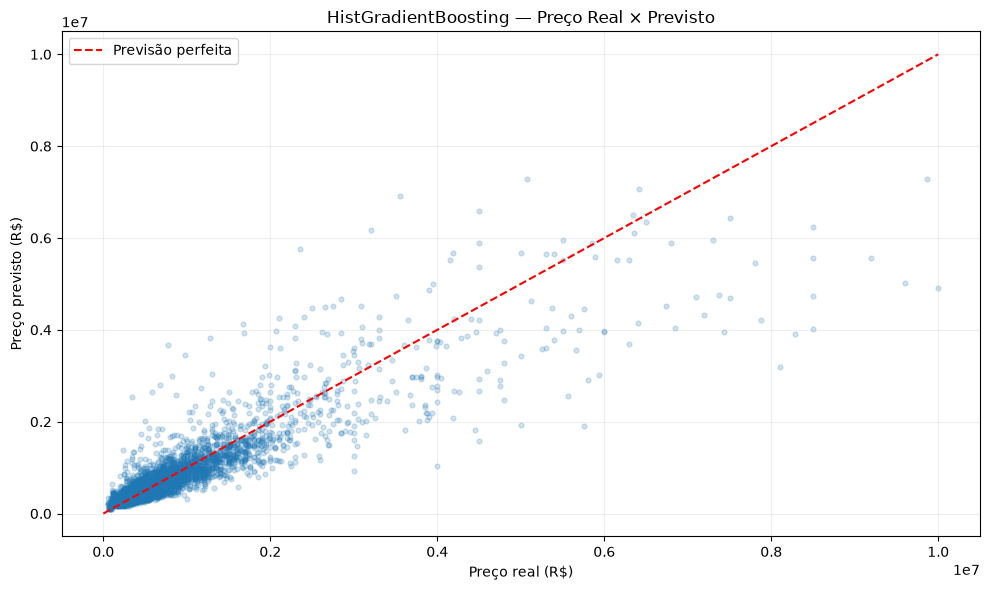


Etapa 09 — Diagnóstico do HGB: OK
Nenhum novo modelo foi treinado.
Conjunto de teste preservado.


In [31]:

# ------------------------------------------------------------
# PROJETO 04 — REAL ESTATE PRICE PREDICTION
# SPRINT 0 — AULA 04
# ETAPA 09 — DIAGNÓSTICO FINAL DOS ERROS DO HGB
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("DIAGNÓSTICO FINAL — HISTGRADIENTBOOSTING")
print("=" * 70)

# ------------------------------------------------------------
# 1. PREPARAR RESULTADOS DA VALIDAÇÃO
# ------------------------------------------------------------

COL_AREA = "Área Construída (m2)"

diagnostico_hgb = pd.DataFrame({
    "preco_real": np.asarray(y_validacao, dtype=float),
    "preco_previsto": np.asarray(
        previsao_hgb_validacao, dtype=float
    ),
    "area": pd.to_numeric(
        validacao[COL_AREA], errors="coerce"
    ).to_numpy(),
    "cep_3": X_validacao["cep_3"].to_numpy(),
})

diagnostico_hgb["erro"] = (
    diagnostico_hgb["preco_real"]
    - diagnostico_hgb["preco_previsto"]
)

diagnostico_hgb["erro_absoluto"] = (
    diagnostico_hgb["erro"].abs()
)

diagnostico_hgb["erro_percentual_absoluto"] = (
    diagnostico_hgb["erro_absoluto"]
    / diagnostico_hgb["preco_real"]
    * 100
)

assert len(diagnostico_hgb) == 5791
assert np.isfinite(
    diagnostico_hgb[
        ["preco_real", "preco_previsto", "erro"]
    ].to_numpy()
).all()

# ------------------------------------------------------------
# 2. RESUMO GERAL
# ------------------------------------------------------------

print("\n1. RESUMO GERAL")
print("-" * 70)

print(
    "Erro médio assinado (real - previsto):",
    f"R$ {diagnostico_hgb['erro'].mean():,.2f}"
)

print(
    "Subestimações:",
    int((diagnostico_hgb["erro"] > 0).sum())
)

print(
    "Superestimações:",
    int((diagnostico_hgb["erro"] < 0).sum())
)

print(
    "Previsões exatas:",
    int((diagnostico_hgb["erro"] == 0).sum())
)

print(
    "Erro percentual absoluto mediano:",
    f"{diagnostico_hgb['erro_percentual_absoluto'].median():.2f}%"
)

print(
    "Previsões com erro percentual acima de 30%:",
    int(
        (
            diagnostico_hgb["erro_percentual_absoluto"]
            > 30
        ).sum()
    )
)

# ------------------------------------------------------------
# 3. FUNÇÃO DE MÉTRICAS POR GRUPO
# ------------------------------------------------------------

def resumir_grupos(dados, coluna):
    resultados = []

    for grupo, parte in dados.groupby(
        coluna, observed=True, dropna=False
    ):
        real = parte["preco_real"].to_numpy()
        erro_abs = parte["erro_absoluto"].to_numpy()

        resultados.append({
            "Grupo": str(grupo),
            "Registros": len(parte),
            "MAE (R$)": erro_abs.mean(),
            "WAPE (%)": (
                erro_abs.sum() / real.sum() * 100
            ),
            "Erro médio (R$)": parte["erro"].mean(),
        })

    return pd.DataFrame(resultados)

# ------------------------------------------------------------
# 4. DESEMPENHO POR FAIXA DE PREÇO
# ------------------------------------------------------------

faixas_preco = [
    0, 300_000, 500_000,
    1_000_000, 2_000_000, np.inf
]

rotulos_preco = [
    "Até R$ 300 mil",
    "R$ 300–500 mil",
    "R$ 500 mil–1 milhão",
    "R$ 1–2 milhões",
    "Acima de R$ 2 milhões",
]

diagnostico_hgb["faixa_preco"] = pd.cut(
    diagnostico_hgb["preco_real"],
    bins=faixas_preco,
    labels=rotulos_preco,
    include_lowest=True,
)

resumo_hgb_preco = resumir_grupos(
    diagnostico_hgb, "faixa_preco"
)

print("\n2. DESEMPENHO POR FAIXA DE PREÇO")
print("-" * 70)

print(
    resumo_hgb_preco.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}"
    )
)

# ------------------------------------------------------------
# 5. DESEMPENHO POR ÁREA
# ------------------------------------------------------------

faixas_area = [0, 50, 100, 150, 250, np.inf]

rotulos_area = [
    "Até 50 m²",
    "50–100 m²",
    "100–150 m²",
    "150–250 m²",
    "Acima de 250 m²",
]

diagnostico_hgb["faixa_area"] = pd.cut(
    diagnostico_hgb["area"],
    bins=faixas_area,
    labels=rotulos_area,
    include_lowest=True,
)

resumo_hgb_area = resumir_grupos(
    diagnostico_hgb, "faixa_area"
)

print("\n3. DESEMPENHO POR FAIXA DE ÁREA")
print("-" * 70)

print(
    resumo_hgb_area.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}"
    )
)

# ------------------------------------------------------------
# 6. DESEMPENHO POR REGIÃO
# ------------------------------------------------------------

resumo_hgb_cep = resumir_grupos(
    diagnostico_hgb, "cep_3"
)

# Considerar apenas grupos com pelo menos 30 registros
resumo_hgb_cep_relevantes = (
    resumo_hgb_cep.loc[
        resumo_hgb_cep["Registros"] >= 30
    ]
    .sort_values("MAE (R$)", ascending=False)
)

print("\n4. REGIÕES COM MAIORES ERROS")
print("-" * 70)

print(
    resumo_hgb_cep_relevantes.head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}"
    )
)

# ------------------------------------------------------------
# 7. VISUALIZAÇÃO DOS ERROS
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    diagnostico_hgb["preco_real"],
    diagnostico_hgb["preco_previsto"],
    alpha=0.20,
    s=12,
)

limite = max(
    diagnostico_hgb["preco_real"].max(),
    diagnostico_hgb["preco_previsto"].max(),
)

plt.plot(
    [0, limite],
    [0, limite],
    linestyle="--",
    color="red",
    label="Previsão perfeita",
)

plt.title(
    "HistGradientBoosting — Preço Real × Previsto"
)
plt.xlabel("Preço real (R$)")
plt.ylabel("Preço previsto (R$)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. CONFERÊNCIA FINAL
# ------------------------------------------------------------

mae_diagnostico = (
    diagnostico_hgb["erro_absoluto"].mean()
)

assert np.isclose(
    mae_diagnostico,
    186687.78,
    atol=0.02,
)

print("\nEtapa 09 — Diagnóstico do HGB: OK")
print("Nenhum novo modelo foi treinado.")
print("Conjunto de teste preservado.")



## Aula 04 — Etapa 10: Avaliação Final no Conjunto de Teste

### 1. Objetivo

Avaliar a capacidade de generalização do HistGradientBoostingRegressor em transações temporalmente posteriores às utilizadas para treinamento e seleção do modelo.

### 2. Protocolo

- Treinamento: janeiro a setembro de 2025.
- Validação: outubro de 2025.
- Teste: novembro e dezembro de 2025.

O modelo foi selecionado exclusivamente com base no desempenho de validação.

### 3. Modelo selecionado

HistGradientBoostingRegressor com quatro atributos:

- Área Construída (m2).
- Fração Ideal.
- Padrão (IPTU).
- Prefixo de três dígitos do CEP.

### 4. Avaliação final

Serão calculadas as métricas:

- MAE.
- RMSE.
- WAPE.

O desempenho do teste será comparado ao resultado obtido na validação.

Também será realizada uma análise descritiva dos erros por mês e por faixa de preço.

### 5. Restrições metodológicas

- Não ajustar hiperparâmetros com base nos resultados do teste.
- Não selecionar novos atributos usando os resultados do teste.
- Não retreinar o modelo nesta etapa.
- Não interpretar o teste como garantia de desempenho futuro.
- Documentar as limitações observadas.

### 6. Critério de conclusão

A etapa estará concluída quando as previsões forem geradas, as métricas calculadas e as diferenças entre validação e teste interpretadas.

**Status:** Em andamento.


In [32]:

# ------------------------------------------------------------
# PROJETO 04 — REAL ESTATE PRICE PREDICTION
# AULA 04 — ETAPA 10
# AVALIAÇÃO FINAL NO CONJUNTO DE TESTE
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
)
from sklearn.utils.validation import check_is_fitted

print("AVALIAÇÃO FINAL — HISTGRADIENTBOOSTING")
print("=" * 70)

# ------------------------------------------------------------
# 1. VERIFICAR PRÉ-REQUISITOS
# ------------------------------------------------------------

necessarias = [
    "teste",
    "modelo_hgb",
    "preparar_atributos",
    "y_validacao",
    "previsao_hgb_validacao",
    "variaveis_modelo",
]

faltantes = [
    nome for nome in necessarias
    if nome not in globals()
]

if faltantes:
    raise RuntimeError(
        f"Execute as etapas anteriores: {faltantes}"
    )

check_is_fitted(modelo_hgb)

COL_PRECO = (
    "Valor de Transação (declarado pelo contribuinte)"
)
COL_DATA = "Data de Transação"

# ------------------------------------------------------------
# 2. PREPARAR CONJUNTO DE TESTE
# ------------------------------------------------------------

X_teste = preparar_atributos(teste)

y_teste = pd.to_numeric(
    teste[COL_PRECO],
    errors="raise",
).to_numpy(dtype=float)

datas_teste = pd.to_datetime(
    teste[COL_DATA],
    errors="raise",
)

assert len(X_teste) == 10105
assert len(y_teste) == 10105
assert list(X_teste.columns) == variaveis_modelo
assert np.isfinite(y_teste).all()
assert (y_teste > 0).all()

assert (
    (datas_teste.dt.year == 2025)
    & (datas_teste.dt.month.isin([11, 12]))
).all()

print("\n1. INTEGRIDADE DO TESTE")
print("-" * 70)
print("Registros:", len(X_teste))
print("Variáveis:", list(X_teste.columns))
print("Período inicial:", datas_teste.min())
print("Período final:", datas_teste.max())

# ------------------------------------------------------------
# 3. PREVISÕES COM O MODELO JÁ TREINADO
# ------------------------------------------------------------

# Não executar fit() ou fit_transform() nesta etapa.

previsao_hgb_teste = np.maximum(
    modelo_hgb.predict(X_teste),
    0,
)

assert len(previsao_hgb_teste) == len(y_teste)
assert np.isfinite(previsao_hgb_teste).all()

print("\n2. PREVISÕES")
print("-" * 70)
print("Previsões geradas:", len(previsao_hgb_teste))
print("Nenhum novo treinamento realizado.")

# ------------------------------------------------------------
# 4. FUNÇÃO DE MÉTRICAS
# ------------------------------------------------------------

def avaliar_final(nome, real, previsto):
    real = np.asarray(real, dtype=float)
    previsto = np.asarray(previsto, dtype=float)

    return {
        "Conjunto": nome,
        "Registros": len(real),
        "MAE (R$)": mean_absolute_error(
            real, previsto
        ),
        "RMSE (R$)": np.sqrt(
            mean_squared_error(real, previsto)
        ),
        "WAPE (%)": (
            np.abs(real - previsto).sum()
            / np.abs(real).sum()
            * 100
        ),
    }

# ------------------------------------------------------------
# 5. COMPARAÇÃO VALIDAÇÃO × TESTE
# ------------------------------------------------------------

metricas_finais = pd.DataFrame([
    avaliar_final(
        "Validação — Outubro",
        y_validacao,
        previsao_hgb_validacao,
    ),
    avaliar_final(
        "Teste — Novembro/Dezembro",
        y_teste,
        previsao_hgb_teste,
    ),
])

print("\n3. MÉTRICAS FINAIS")
print("-" * 70)

print(
    metricas_finais.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# ------------------------------------------------------------
# 6. DIFERENÇA ENTRE VALIDAÇÃO E TESTE
# ------------------------------------------------------------

mae_validacao = metricas_finais.iloc[0]["MAE (R$)"]
mae_teste = metricas_finais.iloc[1]["MAE (R$)"]

variacao_mae_pct = (
    (mae_teste - mae_validacao)
    / mae_validacao
    * 100
)

print("\n4. VARIAÇÃO DO MAE")
print("-" * 70)

print(
    f"Variação do teste em relação à validação: "
    f"{variacao_mae_pct:+.2f}%"
)

# ------------------------------------------------------------
# 7. DIAGNÓSTICO DESCRITIVO DO TESTE
# ------------------------------------------------------------

diagnostico_teste = pd.DataFrame({
    "data": datas_teste.to_numpy(),
    "preco_real": y_teste,
    "preco_previsto": previsao_hgb_teste,
})

diagnostico_teste["erro"] = (
    diagnostico_teste["preco_real"]
    - diagnostico_teste["preco_previsto"]
)

diagnostico_teste["erro_absoluto"] = (
    diagnostico_teste["erro"].abs()
)

diagnostico_teste["mes"] = (
    diagnostico_teste["data"].dt.month
)

def resumir_teste(grupo):
    real = grupo["preco_real"].to_numpy()
    erros = grupo["erro_absoluto"].to_numpy()

    return pd.Series({
        "Registros": len(grupo),
        "MAE (R$)": erros.mean(),
        "WAPE (%)": (
            erros.sum() / real.sum() * 100
        ),
        "Erro médio (R$)": grupo["erro"].mean(),
    })

resumo_teste_mensal = pd.DataFrame([
    {
        "Mês": int(mes),
        **resumir_teste(parte).to_dict(),
    }
    for mes, parte in diagnostico_teste.groupby("mes")
])

print("\n5. RESULTADOS POR MÊS")
print("-" * 70)

print(
    resumo_teste_mensal.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# ------------------------------------------------------------
# 8. RESULTADOS POR FAIXA DE PREÇO
# ------------------------------------------------------------

faixas = [
    0,
    300_000,
    500_000,
    1_000_000,
    2_000_000,
    np.inf,
]

rotulos = [
    "Até R$ 300 mil",
    "R$ 300–500 mil",
    "R$ 500 mil–1 milhão",
    "R$ 1–2 milhões",
    "Acima de R$ 2 milhões",
]

diagnostico_teste["faixa_preco"] = pd.cut(
    diagnostico_teste["preco_real"],
    bins=faixas,
    labels=rotulos,
    include_lowest=True,
)

resumo_teste_preco = pd.DataFrame([
    {
        "Faixa": str(faixa),
        **resumir_teste(parte).to_dict(),
    }
    for faixa, parte in diagnostico_teste.groupby(
        "faixa_preco",
        observed=True,
    )
])

print("\n6. RESULTADOS POR FAIXA DE PREÇO")
print("-" * 70)

print(
    resumo_teste_preco.to_string(
        index=False,
        float_format=lambda x: f"{x:,.2f}",
    )
)

# ------------------------------------------------------------
# 9. VALIDAÇÃO FINAL
# ------------------------------------------------------------

assert np.isclose(
    mae_validacao,
    186687.78,
    atol=0.02,
)

assert (
    resumo_teste_mensal["Registros"].sum()
    == len(teste)
)

assert (
    resumo_teste_preco["Registros"].sum()
    == len(teste)
)

print("\nEtapa 10 — Avaliação final: OK")
print("Modelo original preservado.")
print("Nenhum novo treinamento realizado.")


AVALIAÇÃO FINAL — HISTGRADIENTBOOSTING

1. INTEGRIDADE DO TESTE
----------------------------------------------------------------------
Registros: 10105
Variáveis: ['Área Construída (m2)', 'Fração Ideal', 'Padrão (IPTU)', 'cep_3']
Período inicial: 2025-11-01 00:00:00
Período final: 2025-12-31 00:00:00

2. PREVISÕES
----------------------------------------------------------------------
Previsões geradas: 10105
Nenhum novo treinamento realizado.

3. MÉTRICAS FINAIS
----------------------------------------------------------------------
                 Conjunto  Registros   MAE (R$)  RMSE (R$)  WAPE (%)
      Validação — Outubro       5791 186,687.78 394,139.33     25.52
Teste — Novembro/Dezembro      10105 194,276.29 407,130.39     26.87

4. VARIAÇÃO DO MAE
----------------------------------------------------------------------
Variação do teste em relação à validação: +4.06%

5. RESULTADOS POR MÊS
----------------------------------------------------------------------
 Mês  Registros   MAE


## Aula 05 — Etapa 01: Exportação e Validação do Modelo

### 1. Objetivo

Preparar o modelo HistGradientBoostingRegressor para utilização em uma aplicação de previsão imobiliária.

### 2. Modelo selecionado

O modelo foi selecionado com base na validação temporal e avaliado no conjunto de teste reservado.

Resultados finais:

- MAE: R$ 194.276,29.
- RMSE: R$ 407.130,39.
- WAPE: 26,87%.
- Registros de teste: 10.105.

### 3. Artefatos

Serão gerados dois arquivos:

- `models/modelo_hgb.joblib`: pipeline treinado, incluindo o pré-processamento.
- `models/metadata_modelo.json`: informações sobre variáveis, métricas, períodos e ambiente.

### 4. Verificação de integridade

O modelo será carregado novamente a partir do arquivo salvo.

Suas previsões serão comparadas às previsões produzidas pelo modelo original.

### 5. Restrições

- Nenhum novo treinamento será realizado.
- O conjunto de teste não será utilizado para novos ajustes.
- O modelo exportado deverá preservar o pipeline completo.
- Os arquivos serializados deverão ser carregados somente de fontes confiáveis.

### 6. Limitações

O modelo estima valores declarados de transações imobiliárias, não necessariamente preços de anúncio ou avaliações comerciais.

A aplicação deverá exigir os quatro atributos utilizados no treinamento, inclusive a fração ideal cadastral.

**Status:** Em andamento.


In [33]:

# ------------------------------------------------------------
# PROJETO 04 — REAL ESTATE PRICE PREDICTION
# AULA 05 — ETAPA 01
# EXPORTAÇÃO E VALIDAÇÃO DO MODELO
# ------------------------------------------------------------

from pathlib import Path
from datetime import datetime, timezone
import json
import sys

import joblib
import numpy as np
import pandas as pd
import sklearn

print("EXPORTAÇÃO DO MODELO — HISTGRADIENTBOOSTING")
print("=" * 70)

# ------------------------------------------------------------
# 1. VERIFICAR PRÉ-REQUISITOS
# ------------------------------------------------------------

necessarias = [
    "modelo_hgb",
    "X_validacao",
    "previsao_hgb_validacao",
    "variaveis_modelo",
    "variaveis_numericas",
    "variaveis_categoricas",
    "metricas_finais",
]

faltantes = [
    nome for nome in necessarias
    if nome not in globals()
]

if faltantes:
    raise RuntimeError(
        f"Variáveis ausentes: {faltantes}"
    )

# ------------------------------------------------------------
# 2. DEFINIR DIRETÓRIO DE SAÍDA
# ------------------------------------------------------------

diretorio_projeto = Path.cwd()
diretorio_modelos = diretorio_projeto / "models"

diretorio_modelos.mkdir(
    parents=True,
    exist_ok=True,
)

caminho_modelo = (
    diretorio_modelos / "modelo_hgb.joblib"
)

caminho_metadata = (
    diretorio_modelos / "metadata_modelo.json"
)

print("\n1. DIRETÓRIO DO PROJETO")
print("-" * 70)
print(diretorio_projeto)

# ------------------------------------------------------------
# 3. EXPORTAR PIPELINE COMPLETO
# ------------------------------------------------------------

joblib.dump(
    modelo_hgb,
    caminho_modelo,
    compress=3,
)

print("\n2. MODELO EXPORTADO")
print("-" * 70)
print(caminho_modelo)

# ------------------------------------------------------------
# 4. PREPARAR METADADOS
# ------------------------------------------------------------

linha_teste = metricas_finais.loc[
    metricas_finais["Conjunto"]
    == "Teste — Novembro/Dezembro"
].iloc[0]

metadata = {
    "projeto": "Real Estate Price Prediction",
    "modelo": "HistGradientBoostingRegressor",
    "versao": "1.0.0",
    "data_exportacao_utc": (
        datetime.now(timezone.utc).isoformat()
    ),
    "variavel_alvo": (
        "Valor de Transação "
        "(declarado pelo contribuinte)"
    ),
    "variaveis_entrada": list(
        variaveis_modelo
    ),
    "variaveis_numericas": list(
        variaveis_numericas
    ),
    "variaveis_categoricas": list(
        variaveis_categoricas
    ),
    "periodo_treinamento": (
        "Janeiro a setembro de 2025"
    ),
    "periodo_validacao": "Outubro de 2025",
    "periodo_teste": (
        "Novembro e dezembro de 2025"
    ),
    "metricas_teste": {
        "registros": int(
            linha_teste["Registros"]
        ),
        "mae": float(
            linha_teste["MAE (R$)"]
        ),
        "rmse": float(
            linha_teste["RMSE (R$)"]
        ),
        "wape_percentual": float(
            linha_teste["WAPE (%)"]
        ),
    },
    "ambiente": {
        "python": sys.version.split()[0],
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__,
    },
    "observacoes": [
        "Estimativa do valor declarado na transacao.",
        "Area construida cadastral nao equivale "
        "necessariamente a area privativa.",
        "Fracao ideal e um atributo cadastral.",
        "O prefixo CEP possui tres digitos.",
        "Modelo avaliado em transacoes do "
        "municipio de Sao Paulo.",
        "Nao substitui avaliacao imobiliaria "
        "profissional.",
    ],
}

with open(
    caminho_metadata,
    "w",
    encoding="utf-8",
) as arquivo:
    json.dump(
        metadata,
        arquivo,
        ensure_ascii=False,
        indent=2,
    )

print("\n3. METADADOS EXPORTADOS")
print("-" * 70)
print(caminho_metadata)

# ------------------------------------------------------------
# 5. RECARREGAR MODELO
# ------------------------------------------------------------

# Carregar somente artefatos criados localmente
# ou obtidos de fontes confiáveis.

modelo_recarregado = joblib.load(
    caminho_modelo
)

# ------------------------------------------------------------
# 6. VERIFICAR PREVISÕES
# ------------------------------------------------------------

amostra_verificacao = X_validacao.head(20)

previsoes_recarregadas = np.maximum(
    modelo_recarregado.predict(
        amostra_verificacao
    ),
    0,
)

previsoes_originais = np.asarray(
    previsao_hgb_validacao[:20],
    dtype=float,
)

assert np.allclose(
    previsoes_recarregadas,
    previsoes_originais,
    rtol=1e-10,
    atol=1e-6,
)

print("\n4. VERIFICAÇÃO DE INTEGRIDADE")
print("-" * 70)

print("Registros verificados:", len(amostra_verificacao))
print("Previsões equivalentes: SIM")

# ------------------------------------------------------------
# 7. CONFERIR ARQUIVOS
# ------------------------------------------------------------

print("\n5. ARQUIVOS GERADOS")
print("-" * 70)

for caminho in [
    caminho_modelo,
    caminho_metadata,
]:
    tamanho_kb = caminho.stat().st_size / 1024

    print(
        f"{caminho.name}: "
        f"{tamanho_kb:,.2f} KB"
    )

assert caminho_modelo.is_file()
assert caminho_metadata.is_file()

print("\nAula 05 — Etapa 01: OK")
print("Modelo exportado e recarregado com sucesso.")
print("Nenhum novo treinamento realizado.")


EXPORTAÇÃO DO MODELO — HISTGRADIENTBOOSTING

1. DIRETÓRIO DO PROJETO
----------------------------------------------------------------------
f:\Desktop\PROJETOS\real-estate-price-prediction

2. MODELO EXPORTADO
----------------------------------------------------------------------
f:\Desktop\PROJETOS\real-estate-price-prediction\models\modelo_hgb.joblib

3. METADADOS EXPORTADOS
----------------------------------------------------------------------
f:\Desktop\PROJETOS\real-estate-price-prediction\models\metadata_modelo.json

4. VERIFICAÇÃO DE INTEGRIDADE
----------------------------------------------------------------------
Registros verificados: 20
Previsões equivalentes: SIM

5. ARQUIVOS GERADOS
----------------------------------------------------------------------
modelo_hgb.joblib: 279.45 KB
metadata_modelo.json: 1.33 KB

Aula 05 — Etapa 01: OK
Modelo exportado e recarregado com sucesso.
Nenhum novo treinamento realizado.



## Aula 05 — Etapa 02: Aplicação Web com Streamlit

### 1. Objetivo

Desenvolver uma interface web para realizar previsões utilizando o modelo HistGradientBoostingRegressor previamente treinado.

### 2. Arquitetura

A aplicação utilizará:

- Streamlit para a interface.
- Joblib para carregar o pipeline treinado.
- JSON para consultar os metadados.
- Pandas para preparar os dados de entrada.

### 3. Entradas do modelo

- Área Construída (m2).
- Fração Ideal.
- Padrão (IPTU).
- Prefixo de três dígitos do CEP.

As categorias serão recuperadas do codificador do modelo treinado.

### 4. Saída

A aplicação apresentará uma estimativa do valor declarado da transação, expressa em reais.

### 5. Limitações

O modelo foi desenvolvido com dados de ITBI de apartamentos residenciais do município de São Paulo, referentes a 2025.

A previsão não representa necessariamente o preço anunciado ou o valor de mercado atual.

O resultado não substitui avaliação imobiliária profissional.

### 6. Segurança e reprodutibilidade

O aplicativo carregará apenas o artefato local previamente gerado.

O pipeline não será treinado novamente.

### 7. Critério de conclusão

A etapa será aprovada após executar o Streamlit, preencher o formulário e obter uma previsão sem erros.

**Status:** Em andamento.



## Aula 05 — Etapa 03: Testes Automatizados da Aplicação

### 1. Objetivo

Validar o funcionamento do modelo exportado antes da publicação.

### 2. Estratégia

Utilizar Pytest para verificar:

- Existência dos arquivos do modelo e dos metadados.
- Integridade das variáveis de entrada.
- Carregamento do pipeline treinado.
- Geração de previsões numéricas e finitas.
- Funcionamento com múltiplos registros.
- Tratamento de categorias geográficas não observadas no treinamento.

### 3. Escopo

Os testes avaliam a interface de inferência do modelo, não a precisão comercial das estimativas.

A aplicação Streamlit já foi verificada manualmente.

### 4. Reprodutibilidade

Os testes devem ser executados a partir da raiz do projeto, utilizando o mesmo ambiente virtual do modelo.

### 5. Critério de aprovação

Todos os testes devem passar sem erros.

**Status:** Em andamento.



## Aula 05 — Etapa 04: Preparação das Dependências

### Objetivo

Registrar as dependências necessárias para executar a aplicação Streamlit com o modelo exportado.

### Estratégia

- Identificar as versões instaladas das bibliotecas.
- Criar um arquivo requirements.txt com versões fixadas.
- Verificar a instalação das dependências.
- Preservar o modelo treinado e os resultados da avaliação.

### Critério de conclusão

O arquivo requirements.txt deverá existir na raiz do projeto e as dependências deverão ser reconhecidas pelo ambiente Python.

**Status:** Em andamento.
